# Phase 6: Analysis

We asked what the strictly unpaired CycleGAN (M1) and the weakly paired models, which take composition labels from networks trained on pairs, have learned, using only saved generators scored on 135 validation pairs from 14 donors. At its own accuracy M1 is about as realistic as a blend of unpaired baselines, and the sample-level signal it adds is small: in single-cell → bulk it identifies its sample among the same donor's draws more often than CORAL (within-donor top-1 0.251 against 0.163, fresh seeds) and slightly more often than its mean-shift start (0.193; difference +0.058, 95% CI −0.001 to 0.113), but not more often than ComBat (0.237; difference +0.014, 95% CI −0.034 to 0.066), and in bulk → single-cell not more often than any baseline. Pairs pay off far more as regression targets than as composition labels in accuracy (centered R² 0.173 and 0.272 for ridge on all 68 training donors' pairs, against −0.188 and −0.139 for the weakly paired model with cross-fitted labels, B-cf), and in bulk → single-cell the labels leave composition below the no-pairs ComBat start (B-cf −0.134, 95% CI −0.286 to −0.067). In single-cell → bulk less than half of the weakly paired models' composition gain under the network they train against reaches an independent marker probe (transfer ratio 0.42–0.47, point estimates), while the cycle shows no sign of a low-amplitude hidden channel under our test and no GAN copies its training data. Entropic optimal transport, a non-adversarial unpaired comparator, passes the unpaired accuracy–realism frontier only where it copies or retrieves training profiles; all estimates come from validation donors that also chose the models, so they are optimistic for the models.

## 1. Aim

Phases 3–5 established where the models sit on the accuracy–realism plane: the strictly unpaired CycleGAN lies on the unpaired frontier, and composition labels raise the weakly paired model's composition. This phase asks why, and what these results mean, before the single test evaluation. Does the CycleGAN add anything that a blend of baselines does not? Does the weakly paired model fit the composition network it trains against rather than composition itself? What do the same pairs buy when used as regression targets instead of labels? And is the limit set by adversarial training or by the unpaired setting, as judged by a non-adversarial unpaired comparator?

## 2. Data

- **Training data, as in Phases 3–5: halving 0 of the training split** (582 pairs, 68 donors). A halving divides the training donors into two donor-disjoint halves, A and B (Phase 1, §3.5). The translation models saw the single-cell pseudobulk profiles of half A (33 donors, 288 draws) and the whole-blood bulk profiles of half B (35 donors, 294 draws), and no pair. No translation model was trained in this phase.
- **Fit in this phase, on training data only:**
  - the optimal-transport maps, on the same training halves, and on halving 1 for a sensitivity check;
  - a retrained copy of each composition network, on all 582 training rows, as for the originals;
  - the paired regressions at 33 donors (half A's pairs) and 68 donors (all training pairs);
  - the principal components and per-gene SDs used for the noise checks (training-half targets).
- **Scoring: validation** (135 pairs, 14 donors), with the Phase 1 evaluators, which are fit on training targets only. These are the donors that chose the models' settings and checkpoints, so every validation estimate here is optimistic for the models. The test split is not used.

## 3. Methods

**Notation and metrics** (defined in full in Phase 1, §3, and Phase 3, §3). $x_S$ and $x_B$ are single-cell pseudobulk and whole-blood bulk profiles (log(1 + CP10k) on the 5,000-gene panel), $G$ a generator and $F$ the generator of the opposite direction, $y$ a translation's real partner and $c^*$ the measured composition over six cell-type classes.

- **Centered R²** (accuracy): $1 - \lVert \hat y - y\rVert^2 / \lVert y - \mu\rVert^2$, with $\mu$ the per-gene training mean of the target domain; median over validation pairs.
- **Realism**: $1 - 2\,\lvert \text{AUROC} - 0.5\rvert$ of a classifier two-sample test (C2ST; Lopez-Paz and Oquab, 2017), a logistic regression on the top 10 target principal-component scores and their squares, cross-validated in donor-grouped folds. This measure sees only the top 10 components; Phase 4 (§4.6) gives two 50-component alternatives.
- **Unpaired frontier and margin**: $F(r)$ is the highest realism reached at centered R² of at least $r$ by any blend of two of mean shift, ComBat (Johnson et al., 2007), CORAL (Sun et al., 2016) and the training-target mean, all fit on the training halves; a model at accuracy $r$ and realism $s$ has margin $s - F(r)$.
- **Marker-probe composition R²**: mean over the six classes of the per-class R² of a ridge readout of composition from 28 lineage marker genes (Phase 2), independent of the composition networks $C_S$ and $C_B$ that the weakly paired models train against.
- **Within-donor top-1**: among validation samples whose donor has several draws, the share whose translation is closer (cosine of centered profiles) to its own partner than to the donor's other draws; chance is 0.104 (Phase 1).
- **Start**: each generator starts at an affine baseline map $s(x)$, mean shift in single-cell → bulk and ComBat in bulk → single-cell.

**Models analyzed.** M1 is a CycleGAN (Zhu et al., 2017) with the least-squares adversarial loss (Mao et al., 2017), cycle weight 20 and identity weight 10. M2 adds the composition task loss (Hoffman et al., 2018) through the locked composition networks, which were trained on all training pairs, so pair information reaches M2 through both task terms. B-cf is M2 with bulk composition networks cross-fitted over the 68 training donors, so that each label comes from a network that never saw that row's donor (Phase 5). Three readouts are used and never mixed without a label: the **locked** models at their chosen checkpoints (raw weights, seeds 0–2; selection-biased), **fresh seeds** of the locked settings at steps 15,000, 17,500 and 20,000 (raw weights, seeds 3–5; no checkpoint selection), and **averaged weights** (an exponential moving average of the generator weights, EMA, decay 0.999) at the same three steps for M1, M2 and B-cf (seeds 6–8).

**Analyses.**
- **Matched blend (§4.3).** For each translation set, the blend of two frontier members whose centered R² equals the translation's, found by bisection on the actual blended profiles along every blend path that crosses it, keeping the crossing with the highest realism. We compare the translation with its matched blend on partner discrimination (within-donor top-1 and normalized partner rank), and measure the residual $r = G(x) - \text{blend}(x)$ by its alignment $\Delta_i = \langle r_i/\lVert r_i\rVert, y_i - \bar y_{-i}\rangle$, where $\bar y_{-i}$ is the mean target of the other donors (in genes, and in the top 50 target principal components). Matching on accuracy fixes the residual's projection on the needed correction, so a regression of that correction on the residual would measure only the residual's size; partner discrimination and $\Delta$ are not fixed by the matching.
- **Information-free map (§4.3).** Per gene, a least-squares fit of the generator's outputs on the training-half sources to the mean-shift, ComBat and CORAL translations of the same inputs plus an intercept (no pairs); the share of the generator's validation output variance it explains.
- **Move decomposition (§4.3).** As in Phase 4 (§4.5): the move from the start $\delta = G(x) - s(x)$ against the needed correction $y - s(x)$, split into its length along and across the correction, and the **sample-specific excess**, the median cosine with the needed correction minus the median cosine with another donor's profile in its place.
- **Exploitation check (§4.2).** For each weakly paired model and the M1 runs of the same seeds and steps, the gap closure $g = 1 - \lVert R(G_{M2}(x)) - c^*\rVert_1 / \lVert R(G_{M1}(x)) - c^*\rVert_1$ toward the target the task loss trained on ($c^*$ in single-cell → bulk; the pseudo-label $C_B(x_B)$ in bulk → single-cell), read by four readers $R$: the network the model trained against ($C$), a retrained copy ($C'$: same configuration, epochs and training rows, other member seeds; locked and fresh-seed M2 only), the marker probe and the ridge probe of the Phase 1 evaluators. The transfer ratio is the median $g$ under the marker probe over the median $g$ under $C$. A ratio below 0.5 labels the direction "the generator partly fits its training readout"; when the median $g$ under $C$ is at most 0.1 no ratio is computed. Both rules were fixed before any closure was computed. We also report $C$'s adversarial robustness at the translated inputs, as the median $\varepsilon_{50}$ of the Phase 2 attack (Madry et al., 2018) (the smallest $L_2$ perturbation, as a fraction of the median training deviation, that closes half the gap to another donor's composition).
- **Per-lineage composition (§4.4)**, the **paired-donor curves** (§4.5) and the **same-donor reference** (§4.6): a real profile from another draw of the same donor, scored as a translation (Phase 1, Table 1.9). Similarities in §4.6 are cosines of profiles centered by the target domain's training mean, as in Phase 0.
- **Cycle steganography check (§4.7).** CycleGANs can pass the source through the cycle in small signals that real data do not carry (Chu et al., 2017). We add Gaussian noise $e$ to the translation, in the top 50 principal components of the training-half targets (per-component SD κ times the component's SD), in their orthogonal complement (same total norm) or per gene (SD κ times the gene's SD), κ ∈ {0.01, 0.03, 0.1}, 10 draws per sample, and report the sensitivity ratio $\lVert F(G(x) + e) - F(G(x))\rVert / \lVert F(y + e) - F(y)\rVert$, the median over samples. A ratio far above that of the untrained start would mean the reconstruction leans on signals real profiles do not have.
- **Memorization (§4.8).** The median nearest-neighbor distance from each translation to the training-half targets the discriminator saw, over the same for real validation targets; well below 1 points to copying or to collapse toward training profiles.
- **Entropic optimal transport (§4.1).** A non-adversarial unpaired translator fit on the same training halves: costs are squared distances between the start-mapped sources and the other half's targets in the targets' top 50 principal components, entropic optimal transport (Cuturi, 2013) is solved with uniform weights at regularization ε ∈ {0.01, 0.03, 0.1, 0.3} × the median cost, and a new source maps through the entropic out-of-sample extension (Pooladian and Niles-Weed, 2021) either to the weighted mean of training targets (**OT-b**, barycentric) or to one target drawn with those weights (**OT-s**, 3 draws). Rules fixed before any setting was scored: for each variant the ε with the best margin averaged over directions; for OT-b only settings whose memorization ratio is at least 0.9 in both directions are eligible; OT-s outputs are real training profiles and are read as retrieval, not generation.

**Uncertainty.** Donor-bootstrap 95% CIs (1,000 resamples of the 14 validation donors, the same resamples throughout, with seeds and steps averaged inside each resample; matched blend weights held fixed), and SDs over seeds where stated. These CIs cover donor sampling, not training noise, and come from donors that also chose the models.

## 4. Results

The first code cell records the setup stamp, pins the CPU threads, loads the validation data, evaluators and frontier of halving 0, and reloads the saved generators of Phases 3–5 from their run caches.

In [1]:
import os, sys, json, warnings, hashlib, pickle, itertools
from pathlib import Path
os.environ["PYTHONWARNINGS"] = "ignore:An input array is constant"
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dgm").is_dir())   # repo root, wherever this runs from
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.linalg import LinAlgWarning
from scipy.stats import ConstantInputWarning

from dgm import paths
from dgm import ablation as ab
from dgm import analysis as an
from dgm import composition as comp
from dgm import ot
from dgm import translation as tr
from dgm.baselines import Ridge, RidgeSpread
from dgm.frontier import MEAN, envelope, frontier_margin
from dgm.metrics import GRANULOCYTE, c2st, cosine_matrix, partner_ranks, rowwise_pearson, within_donor_ranks
from dgm.models import load_frozen, pairs_hash, save_frozen, list_hash
from dgm.notebook import setup
from dgm.plotting import DOMAIN, INK, INK_2, MUTED, SERIES, THRESHOLD, figure, label, panel_labels, save_show

warnings.filterwarnings("ignore", category=LinAlgWarning)
warnings.filterwarnings("ignore", category=ConstantInputWarning)
info = setup(seed=0, notebook="phase6_analysis.ipynb")
comp.deterministic()

RESULTS, FIG = paths.results_dir(6), paths.results_dir(6, "figures")
CACHE = paths.PROCESSED / "phase6"; CACHE.mkdir(parents=True, exist_ok=True)
MOD6, REG6 = paths.REPO / "data" / "models" / "phase6", RESULTS / "models.json"
KEEP = (15000, 17500, 20000)
M1 = tr.config(lambda_cyc=20.0, identity=True)                 # the locked settings (Phase 3)
M2 = tr.config(lambda_cyc=20.0, identity=True, lambda_task=10.0)
DEF5 = dict(ema=0.999, keep_states=KEEP)
P5_KEYS = ("identity_target", "identity_dirs", "lambda_dist", "bottleneck")   # options added after Phase 4
KEY4, KEY5 = "4fb36e8a09c74f62", "41dab869bea05335"            # code keys of the Phase 4 and Phase 5 runs
DIRS = tr.DIRECTIONS

# Display names for tables (display only; the CSVs keep their column names and values).
SHOW_COL = {"marker composition R²": "marker-probe composition R²", "median g under C": "median g under C (trained against)",
            "share g > 0.5": "share with g > 0.5", "ratio-of-sums g": "g, ratio of sums", "reading": "reading (rule: ratio < 0.5)",
            "matched": "sets matched", "minus": "reference map", "along": "length along the correction",
            "across": "length across the correction", "SD": "SD over seeds and steps", "partner": "true partner"}
SHOW_VAL = (("averaged (EMA)", "averaged"), (" (EMA)", ", averaged weights"), ("(raw)", "(raw weights)"),
            ("top50", "top 50 PCs"), ("complement", "outside the top 50 PCs"), ("per-gene", "per gene"))
def show_col(c):
    c = SHOW_COL.get(c, c)
    return c[:-3] + ", 95% CI" if isinstance(c, str) and c.endswith(" CI") and "95%" not in c else c
def show_val(v):
    if isinstance(v, str):
        for a, b in SHOW_VAL:
            v = v.replace(a, b)
        return v
    if isinstance(v, float):
        return "—" if v != v else f"{v:g}"
    return str(v)
def tidy(sty):
    """Display names on a table's headers, index labels and text cells."""
    text = [c for c in sty.data.columns if sty.data[c].dtype == object]
    return sty.format_index(show_val, axis=0).format_index(show_col, axis=1).format(show_val, subset=text)

def show_caption(name):
    f = FIG / "captions.md"
    text = f.read_text() if f.exists() else ""
    if f"\n## {name}\n" in text:
        display(Markdown(text.split(f"\n## {name}\n", 1)[1].split("\n## ", 1)[0].strip()))

def cached_run(phase, key, cfg, seed, drop=()):
    """A finished run from its phase's cache (never retrains): the cache name is the hash of the code key, the
    full configuration as it stood in that phase, the seed and the halving."""
    c = {k: v for k, v in tr.config(**cfg).items() if k not in drop}
    name = hashlib.sha256(json.dumps([key, c, seed, 0], sort_keys=True, default=str).encode()).hexdigest()[:16]
    path = paths.PROCESSED / f"phase{phase}" / f"run_{name}.pkl"
    assert path.exists(), f"missing cached run {path.name} (phase {phase}, seed {seed})"
    return pickle.loads(path.read_bytes())

ctx0 = tr.SoundLife(0)
P, va = ctx0.pairs, ctx0.va
tr_idx, ha, hb = P.idx("train"), ctx0.half_a, ctx0.half_b
donors_va, Cv = P.donor_ids[va], P.composition[va]
NG = P.x_sc.shape[1]
digest = pairs_hash(P)

fresh_m1 = [cached_run(4, KEY4, dict(M1, ema=0.999, keep_states=KEEP), s, P5_KEYS) for s in (3, 4, 5)]
fresh_m2 = [cached_run(4, KEY4, dict(M2, keep_states=KEEP), s, P5_KEYS) for s in (3, 4, 5)]
ema_m1 = [cached_run(5, KEY5, dict(M1, **DEF5), s) for s in (6, 7, 8)]
ema_m2 = [cached_run(5, KEY5, dict(M2, **DEF5), s) for s in (6, 7, 8)]
ema_bcf = [cached_run(5, KEY5, dict(M2, task_nets="crossfit", **DEF5), s) for s in (6, 7, 8)]
ema_bk = {k: [cached_run(5, KEY5, dict(M2, task_nets=f"k{k}", **DEF5), s) for s in (6, 7, 8)] for k in (4, 8, 16, 33)}
locked = {m: [torch.load(paths.REPO / "data" / "models" / "phase3" / f"{m}_seed{s}.pt", weights_only=False)["state"] for s in (0, 1, 2)]
          for m in ("M1", "M2")}

# Every analyzed translation set: (state, seed, step) per member, aligned across models of the same seeds and steps.
SETS = {"M1, locked (raw)": [(st, s, None) for s, st in enumerate(locked["M1"])],
        "M2, locked (raw)": [(st, s, None) for s, st in enumerate(locked["M2"])],
        "M1, fresh seeds (raw)": [(r["kept"][k], r["seed"], k) for r in fresh_m1 for k in KEEP],
        "M2, fresh seeds (raw)": [(r["kept"][k], r["seed"], k) for r in fresh_m2 for k in KEEP],
        "M1 (EMA)": [(r["kept_ema"][k], r["seed"], k) for r in ema_m1 for k in KEEP],
        "M2 (EMA)": [(r["kept_ema"][k], r["seed"], k) for r in ema_m2 for k in KEEP],
        "B-cf (EMA)": [(r["kept_ema"][k], r["seed"], k) for r in ema_bcf for k in KEEP]}

def generators(state):
    return tr.load_generators(state, NG, 512)

def apply(gen, x):
    with torch.no_grad():
        return gen(torch.as_tensor(np.asarray(x, np.float32))).numpy()

_OUT = {}
def outputs(name, d, x=None):
    """Translations by every member of a set, of the validation sources (or of x)."""
    key = (name, d, None if x is None else hashlib.sha1(np.ascontiguousarray(x)).hexdigest())
    if key not in _OUT:
        _OUT[key] = [apply(generators(st)[0 if d == "S->B" else 1], ctx0.src[d] if x is None else x) for st, _, _ in SETS[name]]
    return _OUT[key]

def r2_samples(y, d):
    mu, t = ctx0.ev[d].mean_, ctx0.tgt[d]
    return 1 - ((y - t) ** 2).sum(1) / ((t - mu) ** 2).sum(1)
def r2_med(y, d):
    return float(np.median(r2_samples(y, d)))
def realism(y, d, idx=None):
    ev, t = ctx0.ev[d], ctx0.tgt[d]
    idx = np.arange(len(t)) if idx is None else idx
    return 1 - 2 * abs(c2st(ev.pca_.transform(y[idx])[:, :10], ev.pca_.transform(t[idx])[:, :10], donors_va[idx]) - 0.5)
def marker(y, d):
    return ctx0.marker[d].predict(y)
def start_of(d, x=None):
    a0, b0 = ctx0.init[d]
    return np.maximum((ctx0.src[d] if x is None else x) * a0 + b0, 0)

def kept_ema(runs, d, col):
    """(mean, SD) over seeds of each seed's mean over the kept steps, averaged weights (the pre-specified readout)."""
    per_seed = [np.mean([next(e for e in r["evals"] if e["step"] == k)["ema"][f"{d} {col}"] for k in KEEP]) for r in runs]
    return float(np.mean(per_seed)), float(np.std(per_seed, ddof=1))
def weights_of(name):
    return "raw" if "(raw)" in name else "averaged (EMA)" if "(EMA)" in name else "—"

INIT_OF = tr.INIT                                                   # the start of each direction (mean shift, ComBat)
BOOT = an.donor_boot(donors_va, 1000, seed=0)
n_va = len(va)
print("loaded", {k: len(v) for k, v in SETS.items()})

<env>/lib/python3.10/site-packages/torch/cuda/__init__.py:182: UserWarning: CUDA initialization: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 804: forward compatibility was attempted on non supported HW (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:109.)
  return torch._C._cuda_getDeviceCount() > 0


commit: c210e77 | notebook_source: b6570c9fe37d (= HEAD) | python: 3.10.14 | numpy: 1.26.4 | seed: 0 | torch: 2.8.0+cu129 | cuda: False


loaded {'M1, locked (raw)': 3, 'M2, locked (raw)': 3, 'M1, fresh seeds (raw)': 9, 'M2, fresh seeds (raw)': 9, 'M1 (EMA)': 9, 'M2 (EMA)': 9, 'B-cf (EMA)': 9}


In [2]:
# Regeneration check: translations rebuilt from the saved states reproduce the accuracy each run logged at that step
# (raw weights for the locked and fresh-seed runs, averaged weights for the Phase 5 runs), and the Phase 3 chosen models'.
def logged(r, step, d, ema):
    e = next(e for e in r["evals"] if e["step"] == step)
    return (e["ema"] if ema else e)[f"{d} r2_centered"]
for d in DIRS:
    for name, runs, ema in (("M1, fresh seeds (raw)", fresh_m1, False), ("M2, fresh seeds (raw)", fresh_m2, False),
                            ("M1 (EMA)", ema_m1, True), ("M2 (EMA)", ema_m2, True), ("B-cf (EMA)", ema_bcf, True)):
        want = [logged(r, k, d, ema) for r in runs for k in KEEP]
        got = [r2_med(y, d) for y in outputs(name, d)]
        assert np.allclose(got, want, atol=1e-6), (name, d, got, want)
    p3 = pd.read_csv(paths.results_dir(3) / "models_vs_baselines_val.csv")
    for m in ("M1", "M2"):
        want = p3[(p3.direction == label(d)) & (p3.method == f"{m} (mean of 3 seeds)")]["r2_centered"].iloc[0]
        assert abs(np.mean([r2_med(y, d) for y in outputs(f"{m}, locked (raw)", d)]) - want) < 1e-6, (m, d)
# Provenance: each reloaded run is the one its phase reported. Configuration and code key; the locked models' state
# hashes (Phase 3 registry, per seed); last-quarter means of every reloaded run against Phases 4 and 5's per-run tables.
from dgm.models import canonical_hash
P3REG = json.loads((paths.results_dir(3) / "models.json").read_text())
for m in ("M1", "M2"):
    for s, st in enumerate(locked[m]):
        assert canonical_hash(st) == P3REG[f"{m}_seed{s}"]["canonical_hash"], (m, s)
SPEC = [(fresh_m1, dict(M1, ema=0.999, keep_states=KEEP), KEY4, P5_KEYS), (fresh_m2, dict(M2, keep_states=KEEP), KEY4, P5_KEYS),
        (ema_m1, dict(M1, **DEF5), KEY5, ()), (ema_m2, dict(M2, **DEF5), KEY5, ()), (ema_bcf, dict(M2, task_nets="crossfit", **DEF5), KEY5, ()),
        *[(ema_bk[k], dict(M2, task_nets=f"k{k}", **DEF5), KEY5, ()) for k in ema_bk]]
for runs, cfg, key, drop in SPEC:
    want = {k: v for k, v in tr.config(**cfg).items() if k not in drop}
    for r in runs:
        assert r["code_key"] == key and json.dumps(r["cfg"], sort_keys=True, default=str) == json.dumps(want, sort_keys=True, default=str)
abl4 = pd.read_csv(paths.results_dir(4) / "ablation_runs_val.csv")
runs5 = pd.read_csv(paths.results_dir(5) / "runs_val.csv")
def lq(r, d, col, ema):
    return np.mean([(e["ema"] if ema else e)[f"{d} {col}"] for e in r["evals"] if e["step"] >= 15000])
for runs, table, cond, ema in ((fresh_m1, abl4, "full model", False), (fresh_m2, abl4, "B0 M2", False), (ema_m1, runs5, "M1", True),
                               (ema_m2, runs5, "M2", True), (ema_bcf, runs5, "B-cf cross-fitted labels", True),
                               *[(ema_bk[k], runs5, f"B-k{k} labels from {k} donors", True) for k in ema_bk]):
    for r in runs:
        row = table[(table.condition == cond) & (table.seed == r["seed"])].iloc[0]
        for d in DIRS:
            for col in ("r2_centered", "marker comp_r2", "margin"):
                assert abs(lq(r, d, col, ema) - row[f"{d} {col}"]) < 1e-9, (cond, r["seed"], d, col)
print("regeneration: every analyzed set reproduces its logged centered R²; provenance checks pass for every reloaded run")

regeneration: every analyzed set reproduces its logged centered R²; provenance checks pass for every reloaded run


### 4.1 Entropic optimal transport, a non-adversarial unpaired comparator

**No barycentric setting passes the memorization rule, and every optimal-transport setting that passes the frontier copies or retrieves training profiles.**

**Table 6.1** (OT-b) and **Table 6.2** (OT-s). The four regularization settings on the 135 validation pairs (14 donors), per direction: margin beyond the unpaired frontier, centered R², realism, marker-probe composition R², within-donor top-1 and the memorization ratio (to the training halves). OT-s values are means over 3 draws.

**Table 6.2 (continued).** Donor-bootstrap 95% CIs of centered R², marker-probe composition R² and within-donor top-1 for every setting. Margins and realism have no validation CI here; the classifier-test bootstrap is run only in the test evaluation.

**Table 6.3.** The margin of the chosen setting on halving 0 and, refit at the same ε, on halving 1, next to the locked M1 (chosen checkpoints, mean of seeds 0–2).

In [3]:
# Entropic OT on the training halves (§3): costs between start-mapped sources and the other half's targets in
# the targets' top 50 PCs; 4 regularization settings; OT-b (barycentric) and OT-s (one conditional draw, 3 seeds).
ctx1 = tr.SoundLife(1)
def ot_fit(ctx, d, eps_rel):
    a0, b0 = ctx.init[d]
    src, tgt = (ctx.xs, ctx.xb) if d == "S->B" else (ctx.xb, ctx.xs)
    return ot.EntropicOT(eps_rel, lambda x: np.maximum(x * a0 + b0, 0)).fit(np.asarray(src, float), np.asarray(tgt, float))

def train_half_targets(ctx, d):
    return np.asarray(ctx.xb if d == "S->B" else ctx.xs, float)
def nn_ratio(y, ref, d):
    """Median nearest-neighbor distance from translations to `ref`, over the same for the real validation targets."""
    def nn(a):
        return np.sqrt(np.maximum((a * a).sum(1)[:, None] + (ref * ref).sum(1)[None, :] - 2 * a @ ref.T, 0)).min(1)
    return float(np.median(nn(y)) / np.median(nn(ctx0.tgt[d])))

def ranks_ot(y, d):
    mu = ctx0.ev[d].mean_
    w = within_donor_ranks(cosine_matrix(y - mu, ctx0.tgt[d] - mu), donors_va)
    return np.where(np.isnan(w), np.nan, (w == 1).astype(float))
def score_row(y, d, ctx=ctx0):
    r2, real = r2_med(y, d), realism(y, d)
    sim = cosine_matrix(y - ctx0.ev[d].mean_, ctx0.tgt[d] - ctx0.ev[d].mean_)
    w = within_donor_ranks(sim, donors_va)
    return {"margin": frontier_margin(ctx.frontier[d], r2, real)[0], "margin kind": frontier_margin(ctx.frontier[d], r2, real)[1],
            "centered R²": r2, "realism": real, "marker composition R²": comp.comp_r2(marker(y, d), Cv),
            "within-donor top-1": float(np.nanmean(w[~np.isnan(w)] == 1)), "memorization ratio (training halves)": nn_ratio(y, train_half_targets(ctx, d), d)}

OT_FITS, ot_rows, OT_OUT = {}, [], {}
for eps in ot.EPS_GRID:
    for d in DIRS:
        m = OT_FITS[(eps, d)] = ot_fit(ctx0, d, eps)
        OT_OUT[("OT-b", eps, d)] = [m.translate(np.asarray(ctx0.src[d], float))]
        OT_OUT[("OT-s", eps, d)] = [m.sample(np.asarray(ctx0.src[d], float), seed=s)[0] for s in (0, 1, 2)]
        for var in ("OT-b", "OT-s"):
            rows = [score_row(y, d) for y in OT_OUT[(var, eps, d)]]
            ot_rows.append({"variant": var, "eps": eps, "direction": label(d), "Sinkhorn iterations": m.iters_,
                            **pd.DataFrame(rows).mean(numeric_only=True).to_dict(),
                            "margin kind": rows[0]["margin kind"],
                            **({"margin SD over draws": float(pd.DataFrame(rows)["margin"].std())} if var == "OT-s" else {})})
ot_tab = pd.DataFrame(ot_rows)
ot_tab.to_csv(RESULTS / "ot_sweep_val.csv", index=False)

# Selection rule (fixed before any setting was scored): best validation margin averaged over directions; for OT-b an eps is eligible only
# if its training-half memorization ratio is at least 0.9 in both directions.
def choose(var, gate):
    t = ot_tab[ot_tab.variant == var]
    ok = {e: bool((t[t.eps == e]["memorization ratio (training halves)"] >= 0.9).all()) for e in ot.EPS_GRID}
    mean_margin = t.groupby("eps")["margin"].mean()
    elig = [e for e in ot.EPS_GRID if (not gate or ok[e])]
    return (max(elig, key=lambda e: mean_margin[e]) if elig else None), mean_margin, ok
EPS_B, mm_b, ok_b = choose("OT-b", True)
EPS_S, mm_s, _ = choose("OT-s", False)
print("OT-b eligible settings:", [e for e in ot.EPS_GRID if ok_b[e]], "| chosen eps:", EPS_B, "| OT-s chosen eps:", EPS_S)
OT_SHOW = {"eps": "ε (× median cost)", "margin": "margin", "centered R²": "centered R²", "realism": "realism",
           "marker composition R²": "marker-probe composition R²", "within-donor top-1": "within-donor top-1",
           "memorization ratio (training halves)": "memorization ratio"}
oc_rows = []
for (var, eps, d), ys in OT_OUT.items():
    row = {"variant": var, "ε (× median cost)": eps, "direction": label(d)}
    w1 = [ranks_ot(y, d) for y in ys]
    for lab_, st in (("centered R²", lambda idx: np.mean([np.median(r2_samples(y, d)[idx]) for y in ys])),
                     ("marker-probe composition R²", lambda idx: np.mean([comp.comp_r2(marker(y, d)[idx], Cv[idx]) for y in ys])),
                     ("within-donor top-1", lambda idx: np.mean([np.nanmean(w[idx]) for w in w1]))):
        e, lo, hi = an.ci(st, n_va, BOOT)
        row[lab_], row[f"{lab_}, 95% CI"] = e, f"{lo:.3f} to {hi:.3f}"
    oc_rows.append(row)
oc_tab = pd.DataFrame(oc_rows).sort_values(["variant", "direction", "ε (× median cost)"], kind="stable")
oc_tab.to_csv(RESULTS / "ot_sweep_ci_val.csv", index=False)
for var in ("OT-b", "OT-s"):
    t = ot_tab[ot_tab.variant == var].pivot(index="eps", columns="direction", values=[c for c in OT_SHOW if c != "eps"])
    t = t.swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
    t.columns = pd.MultiIndex.from_tuples([(a, OT_SHOW[b]) for a, b in t.columns])
    t.index.name = OT_SHOW["eps"]
    display(tidy(t[[c for d in DIRS for c in t.columns if c[0] == label(d)]].style.format("{:.3f}")
            .set_caption(f"Table 6.{1 if var == 'OT-b' else 2}. {var}: the four regularization settings, validation")))
display(tidy(oc_tab.style.format("{:.3f}", subset=["centered R²", "marker-probe composition R²", "within-donor top-1"]).format("{:g}", subset=["ε (× median cost)"]).hide(axis="index")
        .set_caption("Table 6.2 (continued). Optimal transport: donor-bootstrap 95% CIs of the readouts that do not need the classifier test, validation")))

OT-b eligible settings: [] | chosen eps: None | OT-s chosen eps: 0.3


variant,ε (× median cost),direction,centered R²,"centered R², 95% CI",marker-probe composition R²,"marker-probe composition R², 95% CI",within-donor top-1,"within-donor top-1, 95% CI"
OT-b,0.01,bulk → single-cell,-0.294,-0.511 to -0.126,-0.375,-1.012 to -0.167,0.170,0.125 to 0.217
OT-b,0.03,bulk → single-cell,-0.044,-0.249 to 0.054,-0.175,-0.720 to 0.020,0.193,0.148 to 0.242
OT-b,0.1,bulk → single-cell,0.083,-0.040 to 0.161,0.040,-0.306 to 0.139,0.170,0.133 to 0.215
OT-b,0.3,bulk → single-cell,0.082,0.029 to 0.158,0.043,-0.308 to 0.110,0.163,0.130 to 0.200
OT-b,0.01,single-cell → bulk,-0.441,-0.554 to -0.297,0.105,-0.238 to 0.213,0.230,0.174 to 0.289
OT-b,0.03,single-cell → bulk,-0.170,-0.265 to -0.027,0.230,-0.017 to 0.311,0.193,0.126 to 0.268
OT-b,0.1,single-cell → bulk,-0.015,-0.096 to 0.067,0.209,-0.008 to 0.262,0.156,0.098 to 0.216
OT-b,0.3,single-cell → bulk,-0.017,-0.074 to 0.047,0.093,-0.129 to 0.136,0.133,0.094 to 0.176
OT-s,0.01,bulk → single-cell,-0.446,-0.713 to -0.307,-0.691,-1.455 to -0.465,0.138,0.102 to 0.180
OT-s,0.03,bulk → single-cell,-0.562,-0.704 to -0.355,-0.807,-1.726 to -0.567,0.111,0.081 to 0.140


In [4]:
# OT on halving 1 at the eps chosen on halving 0 (no re-selection), next to M1's halving-1 margins (Phase 3).
h1 = pd.read_csv(paths.results_dir(3) / "halving_sensitivity_val.csv")
h1_rows = []
p3m = pd.read_csv(paths.results_dir(3) / "models_vs_baselines_val.csv")
for var, eps in (("OT-b", EPS_B), ("OT-s", EPS_S)):
    if eps is None:
        continue
    for d in DIRS:
        m = ot_fit(ctx1, d, eps)
        ys = [m.translate(np.asarray(ctx1.src[d], float))] if var == "OT-b" else [m.sample(np.asarray(ctx1.src[d], float), seed=s)[0] for s in (0, 1, 2)]
        h1_rows.append({"model": var, "direction": label(d),
                        "margin, halving 0": ot_tab[(ot_tab.variant == var) & (ot_tab.eps == eps) & (ot_tab.direction == label(d))]["margin"].iloc[0],
                        "margin, halving 1": np.mean([frontier_margin(ctx1.frontier[d], r2_med(y, d), realism(y, d))[0] for y in ys])})
for d in DIRS:
    h1_rows.append({"model": "M1 (locked, raw)", "direction": label(d),
                    "margin, halving 0": p3m[(p3m.direction == label(d)) & (p3m.method == "M1 (mean of 3 seeds)")]["margin at the chosen checkpoint"].iloc[0],
                    "margin, halving 1": h1[(h1.model == "M1") & (h1.halving == 1)][f"{label(d)} margin"].mean()})
h1_tab = pd.DataFrame(h1_rows)
h1_tab.to_csv(RESULTS / "ot_halving1_val.csv", index=False)
display(tidy(h1_tab.style.format("{:.3f}", subset=["margin, halving 0", "margin, halving 1"]).hide(axis="index")
        .set_caption("Table 6.3. Margin beyond the unpaired frontier on the two halvings, validation")))

model,direction,"margin, halving 0","margin, halving 1"
OT-s,single-cell → bulk,-0.108,-0.074
OT-s,bulk → single-cell,0.212,-0.107
"M1 (locked, raw)",single-cell → bulk,0.023,0.094
"M1 (locked, raw)",bulk → single-cell,-0.026,-0.332


- **OT-b passes the frontier only with outputs close to training profiles.** At the smallest regularization its margins are +0.051 and +0.047, with memorization ratios of 0.344 and 0.185: near-copies of single training profiles. In bulk → single-cell it also passes the frontier at ε = 0.03 (+0.068, larger than the locked M1's −0.026) and ε = 0.1 (+0.006), with memorization ratios of 0.550 and 0.673; by the rule fixed in advance, a margin above 0 with a memorization ratio well below 1 is read as copying, not information. In single-cell → bulk those settings are inside the frontier (−0.039, −0.115), and at ε = 0.3 both directions collapse toward the training mean (realism 0.004 and 0.009).
- **No OT-b setting is eligible.** None reaches a memorization ratio of 0.9 in both directions, so OT-b has no eligible setting and does not go to test. The rule is stricter than copying alone: shrinkage toward the mean also lowers the ratio, and in single-cell → bulk the start (0.870) and paired ridge + spread (0.793) would fail it too (Table 6.19).
- **OT-s, a retrieval model, passes the frontier on realism alone in bulk → single-cell.** At its chosen ε = 0.3 its margin is +0.212 there (−0.108 in single-cell → bulk), with centered R² of −0.787 (95% CI −0.951 to −0.657) and a cosine to the true partner of 0.075 (Table 6.17): realistic profiles that carry almost nothing about the source. Refit on halving 1, that margin falls to −0.107 (Table 6.3).
- **Interpretation.** The one non-adversarial unpaired map we tried passes the frontier only by copying or retrieving, so it gives no evidence that another unpaired method would escape the limit M1 hits; it does not show that none could. Profiles that carry no information about the source can pass the frontier, which bounds what a positive margin can mean.

### 4.2 Does the weakly paired model exploit its composition network?

**In single-cell → bulk, less than half of the weakly paired models' gain under the composition network they trained against reaches the marker probe; a retrained copy of the network sees almost all of it.**

**Table 6.4.** Median gap closure $g$ toward the training target (the source draw's measured composition in single-cell → bulk; the bulk pseudo-label in bulk → single-cell), per reader, on the 135 validation pairs (14 donors), for three comparisons: locked M2 against locked M1 (chosen checkpoints, seeds 0–2), M2 against M1 on fresh seeds (seeds 3–5 at the three kept steps, paired by seed and step), and B-cf against M1 with averaged weights (seeds 6–8, kept steps). The retrained copy is defined only for the locked networks.

**Table 6.5.** The transfer ratios (median $g$ under the reader over median $g$ under the trained-against network), the donor-bootstrap 95% CI of the marker-probe ratio, and the reading given by the rule of §3.

**Table 6.6.** Bulk → single-cell closure toward the measured composition instead of the pseudo-label (the comparison that hypothesis H2 makes): median $g$, the share of samples with $g > 0.5$, and $g$ with the gaps summed over all samples before the ratio is taken.

**Table 6.7.** Median $\varepsilon_{50}$ of the composition network at real validation inputs and at the models' translations (higher is more robust).

In [5]:
# Readers: the network the model trained against (C), a retrained copy (C', locked and fresh-seed M2 only), the marker
# probe (decision probe) and the ridge probe (secondary). C' uses the Phase 2 configuration, epochs and training rows,
# with member seeds 3-5.
reg2 = json.loads((paths.results_dir(2) / "models.json").read_text())
reg6 = json.loads(REG6.read_text()) if REG6.exists() else {}
for name, dom in (("C_bulk", "bulk"), ("C_sc", "sc")):
    e6 = reg6.get(f"{name}_retrained")
    if e6 is None or e6["config"] != reg2[name]["config"] or e6["epochs"] != reg2[name]["epochs"] or e6.get("member_seeds") != [3, 4, 5]:
        nets, mean, inv, prior = comp.freeze_nets(P, tr_idx, dom, reg2[name]["config"], reg2[name]["epochs"], seeds=(3, 4, 5))
        save_frozen(f"{name}_retrained", nets, reg2[name]["config"], mean, inv, prior, MOD6, REG6,
                    {"epochs": reg2[name]["epochs"], "classes": P.l1_classes.tolist(), "genes_hash": list_hash(P.genes.tolist()),
                     "pairs_hash": digest, "member_seeds": [3, 4, 5], "trained_on": f"all {len(tr_idx)} training rows (as the locked {name})"})
        reg6 = json.loads(REG6.read_text())
ld = lambda name, mod, reg: load_frozen(name, mod, reg, ctx0.genes, ctx0.classes, digest)
C_re = {"S->B": ld("C_bulk_retrained", MOD6, REG6), "B->S": ld("C_sc_retrained", MOD6, REG6)}
reg5p, mod5p = paths.results_dir(5) / "models.json", paths.REPO / "data" / "models" / "phase5"
class MeanOf(torch.nn.Module):
    def __init__(self, nets):
        super().__init__(); self.nets = torch.nn.ModuleList(nets)
    def forward(self, x):
        return torch.stack([n(x) for n in self.nets]).mean(0)
cf68 = MeanOf([ld(f"C_bulk_cf68_f{f}", mod5p, reg5p) for f in range(5)])     # B-cf's bulk networks; all out of sample on validation
cs_halfA = ld("C_sc_halfA0", paths.REPO / "data" / "models" / "phase4", paths.results_dir(4) / "models.json")
def read(net, y):
    with torch.no_grad():
        return net(torch.as_tensor(np.asarray(y, np.float32))).numpy()

COMPARE = {"locked M2 vs. locked M1 (raw)": ("M2, locked (raw)", "M1, locked (raw)", "locked"),
           "M2 vs. M1, fresh seeds (raw)": ("M2, fresh seeds (raw)", "M1, fresh seeds (raw)", "locked"),
           "B-cf vs. M1 (EMA)": ("B-cf (EMA)", "M1 (EMA)", "crossfit")}
def readers(d, nets):
    C = (ctx0.nets[d] if nets == "locked" else (cf68 if d == "S->B" else cs_halfA))
    out = {"C (trained against)": lambda y: read(C, y)}
    if nets == "locked":
        out["C′ (retrained copy)"] = lambda y: read(C_re[d], y)
    out["marker probe"] = lambda y: marker(y, d)
    out["ridge probe"] = lambda y: ctx0.ev[d].comp_probe_.predict(y)
    return C, out
def c_star(d, nets):
    if d == "S->B":
        return Cv                                                          # the source draw's measured composition
    return read(ctx0.nets["S->B"] if nets == "locked" else cf68, P.x_bulk[va])   # the pseudo-label C_B(x_B)

g_rows, G_PER = [], {}
for d in DIRS:
    for cname, (a, b, nets) in COMPARE.items():
        _, R = readers(d, nets)
        targets = {"training target": c_star(d, nets)} if d == "S->B" else {"training target": c_star(d, nets), "measured composition": Cv}
        for tname, cst in targets.items():
            for rname, f in R.items():
                pairs_ = list(zip(outputs(a, d), outputs(b, d)))
                if tname == "training target":
                    G_PER[(label(d), cname, rname)] = [an.gap_closure(f(ya), f(yb), cst) for ya, yb in pairs_]
                summ = pd.DataFrame([an.closure_summary(f(ya), f(yb), cst) for ya, yb in pairs_]).mean()
                g_rows.append({"direction": label(d), "comparison": cname, "target c*": tname, "reader": rname, **summ.to_dict()})
g_tab = pd.DataFrame(g_rows)
ratio_rows = []
for (dl, cname), t in g_tab[g_tab["target c*"] == "training target"].groupby(["direction", "comparison"], sort=False):
    gc = t.set_index("reader")["median g"]
    row = {"direction": dl, "comparison": cname, "median g under C": gc["C (trained against)"],
           "transfer ratio, marker probe": an.transfer_ratio(gc["marker probe"], gc["C (trained against)"]),
           "transfer ratio, ridge probe": an.transfer_ratio(gc["ridge probe"], gc["C (trained against)"])}
    if "C′ (retrained copy)" in gc:
        row["transfer ratio, C′"] = an.transfer_ratio(gc["C′ (retrained copy)"], gc["C (trained against)"])
    gm, gC = G_PER[(dl, cname, "marker probe")], G_PER[(dl, cname, "C (trained against)")]
    e, lo, hi = an.ci(lambda idx: an.transfer_ratio(np.mean([np.nanmedian(g[idx]) for g in gm]), np.mean([np.nanmedian(g[idx]) for g in gC])), n_va, BOOT)
    row["transfer ratio, marker probe, 95% CI"] = f"{lo:.3f} to {hi:.3f}"
    tr_m = row["transfer ratio, marker probe"]
    row["reading"] = ("no closure under C" if np.isnan(tr_m) else
                      "partly fits its training readout" if tr_m < 0.5 else "transfers to the marker probe")
    ratio_rows.append(row)
ratio_tab = pd.DataFrame(ratio_rows)
g_tab.to_csv(RESULTS / "exploitation_closure_val.csv", index=False)
ratio_tab.to_csv(RESULTS / "exploitation_transfer_val.csv", index=False)
show = g_tab[g_tab["target c*"] == "training target"].pivot_table(index=["direction", "comparison"], columns="reader", values="median g", sort=False)
display(tidy(show[[c for c in ("C (trained against)", "C′ (retrained copy)", "marker probe", "ridge probe") if c in show.columns]]
        .style.format("{:.3f}", na_rep="").set_caption("Table 6.4. Median gap closure toward the training target, validation")))
display(tidy(ratio_tab.style.format("{:.3f}", na_rep="—", subset=[c for c in ratio_tab.columns if c not in ("direction", "comparison", "reading") and not c.endswith("CI")])
        .hide(axis="index").set_caption("Table 6.5. Transfer of the gain under C to the other readers")))
display(tidy(g_tab[g_tab["target c*"] == "measured composition"].drop(columns="target c*").style.format("{:.3f}", subset=["median g", "share g > 0.5", "ratio-of-sums g"])
        .hide(axis="index").set_caption("Table 6.6. Bulk → single-cell gap closure toward the measured composition (pair truth), validation")))

direction,comparison,median g under C (trained against),"transfer ratio, marker probe","transfer ratio, ridge probe","transfer ratio, C′","transfer ratio, marker probe, 95% CI",reading (rule: ratio < 0.5)
single-cell → bulk,locked M2 vs. locked M1 (raw weights),0.475,0.466,0.890,0.949,0.288 to 0.671,partly fits its training readout
single-cell → bulk,"M2 vs. M1, fresh seeds (raw weights)",0.513,0.419,0.821,0.966,0.347 to 0.491,partly fits its training readout
single-cell → bulk,"B-cf vs. M1, averaged weights",0.413,0.451,0.903,—,0.352 to 0.555,partly fits its training readout
bulk → single-cell,locked M2 vs. locked M1 (raw weights),0.402,0.615,0.909,0.879,0.445 to 0.862,transfers to the marker probe
bulk → single-cell,"M2 vs. M1, fresh seeds (raw weights)",0.454,0.609,0.904,0.925,0.476 to 0.774,transfers to the marker probe
bulk → single-cell,"B-cf vs. M1, averaged weights",0.457,0.487,0.849,—,0.389 to 0.582,partly fits its training readout


direction,comparison,reader,median g,share with g > 0.5,"g, ratio of sums"
bulk → single-cell,locked M2 vs. locked M1 (raw weights),C (trained against),0.239,0.198,0.257
bulk → single-cell,locked M2 vs. locked M1 (raw weights),C′ (retrained copy),0.193,0.153,0.206
bulk → single-cell,locked M2 vs. locked M1 (raw weights),marker probe,0.191,0.126,0.198
bulk → single-cell,locked M2 vs. locked M1 (raw weights),ridge probe,0.233,0.202,0.259
bulk → single-cell,"M2 vs. M1, fresh seeds (raw weights)",C (trained against),0.271,0.209,0.260
bulk → single-cell,"M2 vs. M1, fresh seeds (raw weights)",C′ (retrained copy),0.223,0.165,0.204
bulk → single-cell,"M2 vs. M1, fresh seeds (raw weights)",marker probe,0.177,0.099,0.169
bulk → single-cell,"M2 vs. M1, fresh seeds (raw weights)",ridge probe,0.267,0.200,0.260
bulk → single-cell,"B-cf vs. M1, averaged weights",C (trained against),0.252,0.181,0.261
bulk → single-cell,"B-cf vs. M1, averaged weights",marker probe,0.159,0.062,0.158


In [6]:
# eps50 of C at the translated inputs against real inputs of that domain (Phase 2 attack; targets: another donor's composition).
# The attack runs once and is cached (it is the slow step of this notebook).
val_attack = pd.read_csv(paths.results_dir(2) / "val_attack.csv")
t_idx = comp.pick_targets(donors_va)
c_t = torch.as_tensor(Cv[t_idx], dtype=torch.float32)
def scale_of(d):
    X = np.asarray((P.x_bulk if d == "S->B" else P.x_sc)[tr_idx], float)
    return float(np.median(np.linalg.norm(X - X.mean(0), axis=1)))
jobs = {}
for d in DIRS:
    for s in range(3):
        jobs[("locked M2", d, s)] = (ctx0.nets[d], outputs("M2, locked (raw)", d)[s])
    for i, (_, seed, step) in enumerate(SETS["B-cf (EMA)"]):
        if step == 20000:
            jobs[("B-cf", d, seed)] = (cf68 if d == "S->B" else cs_halfA, outputs("B-cf (EMA)", d)[i])
    jobs[("B-cf network, real inputs", d, None)] = (cf68 if d == "S->B" else cs_halfA, ctx0.tgt[d])
SMOKE = os.environ.get("PHASE6_SMOKE") == "1"                    # a fast pass over 6 samples, for testing the code only
if SMOKE:
    jobs = {j: (net, x[:6]) for j, (net, x) in jobs.items()}
att_path = CACHE / ("eps50_smoke.pkl" if SMOKE else "eps50.pkl")
net_bytes = b"".join(p.detach().numpy().tobytes() for net in {id(n): n for n, _ in jobs.values()}.values() for p in net.state_dict().values())
key = hashlib.sha256(b"".join(np.ascontiguousarray(x, np.float32).tobytes() for _, x in jobs.values()) + c_t.numpy().tobytes() + net_bytes
                     + json.dumps([sorted(map(str, jobs)), SMOKE]).encode()).hexdigest()
att = pickle.loads(att_path.read_bytes()) if att_path.exists() else {}
if att.get("key") != key:
    import time; t0 = time.time()
    kw = dict(iters=2, steps=20, restarts=1) if SMOKE else {}
    att = {"key": key, "eps50": {j: comp.eps50(net, torch.as_tensor(np.asarray(x, np.float32)), c_t[:len(x)], scale_of(j[1]), **kw)
                                 for j, (net, x) in jobs.items()}}
    att["minutes"] = (time.time() - t0) / 60
    att_path.write_bytes(pickle.dumps(att))
real_ref = {d: val_attack[(val_attack.domain == ("bulk" if d == "S->B" else "sc")) & (val_attack.model == "net")]["eps50_median"].iloc[0] for d in DIRS}
e_rows = []
for d in DIRS:
    e_rows.append({"direction": label(d), "network": "locked", "ε₅₀ at real inputs": real_ref[d],
                   "ε₅₀ at translated inputs": np.mean([np.median(att["eps50"][("locked M2", d, s)]) for s in range(3)]), "translations": "locked M2, seeds 0–2"})
    e_rows.append({"direction": label(d), "network": "B-cf's", "ε₅₀ at real inputs": float(np.median(att["eps50"][("B-cf network, real inputs", d, None)])),
                   "ε₅₀ at translated inputs": np.mean([np.median(att["eps50"][("B-cf", d, s)]) for s in (6, 7, 8)]), "translations": "B-cf, seeds 6–8, step 20,000"})
eps_tab = pd.DataFrame(e_rows)
eps_tab.to_csv(RESULTS / "exploitation_eps50_val.csv", index=False)
print(f"attack: {att.get('minutes', float('nan')):.1f} minutes")
display(tidy(eps_tab.style.format("{:.4f}", subset=["ε₅₀ at real inputs", "ε₅₀ at translated inputs"]).hide(axis="index")
        .set_caption("Table 6.7. Median ε₅₀ of the composition network at real and at translated inputs, validation")))

attack: 7.0 minutes


direction,network,ε₅₀ at real inputs,ε₅₀ at translated inputs,translations
single-cell → bulk,locked,0.0310,0.0348,"locked M2, seeds 0–2"
single-cell → bulk,B-cf's,0.0402,0.0433,"B-cf, seeds 6–8, step 20,000"
bulk → single-cell,locked,0.0464,0.0409,"locked M2, seeds 0–2"
bulk → single-cell,B-cf's,0.0610,0.0557,"B-cf, seeds 6–8, step 20,000"


- **Single-cell → bulk: the label "the generator partly fits its training readout" applies to all three comparisons.** The trained-against network sees closure of 0.413–0.513, the marker probe 0.186–0.221: transfer ratios of 0.466 (95% CI 0.288–0.671; locked), 0.419 (95% CI 0.347–0.491; fresh seeds) and 0.451 (95% CI 0.352–0.555; B-cf). The rule acts on point estimates; only the fresh-seed CI lies wholly below 0.5, and the locked and B-cf CIs include it. The ridge probe sees most of the gain (ratio 0.821–0.903).
- **Bulk → single-cell: the label applies to B-cf only, and narrowly.** Locked and fresh-seed M2 transfer 0.615 and 0.609 of their gain to the marker probe; B-cf transfers 0.487 (95% CI 0.389–0.582), so its label rests on a point estimate at the threshold.
- **The retrained copy sees almost the same gain** (ratio 0.949 and 0.966 in single-cell → bulk, 0.879 and 0.925 in bulk → single-cell), so the gain is not tied to the particular weights the model trained against. The composition networks are linear readouts trained on the same rows, so the copy differs from the original mainly in training order; it rules out exploitation of one seed, not of the network family. The disagreement is between the composition networks, which read all 5,000 genes, and the 28-marker probe, which in single-cell → bulk recovers composition from real bulk only moderately (0.463, Table 6.12).
- **Against the measured composition** (Table 6.6), the bulk → single-cell closure is smaller under every reader (0.159–0.271), and smaller under the marker probe than under the trained-against network in all three comparisons.
- **The translations are about as easy to attack as real inputs.** Median $\varepsilon_{50}$ at the translations is 0.0348 against 0.0310 at real bulk inputs, and 0.0409 against 0.0464 at real single-cell inputs, for the locked networks; 0.0433 against 0.0402 and 0.0557 against 0.0610 for B-cf's (Table 6.7). Each value at the translations is within 15% of the one at real inputs (point estimates), so the generators do not move their outputs into regions where small, non-biological changes swing the network.

### 4.3 Is the strictly unpaired model a blend of baselines?

**At its own accuracy, M1 is about as realistic as a blend of baselines, and the sample-level signal it adds over the unpaired maps is small and limited to single-cell → bulk.**

**Table 6.8.** Each translation set against its matched blend (§3) on the 135 validation pairs (14 donors): the blend paths used, realism of the blend minus that of the translation, within-donor top-1 of each, and the differences in within-donor top-1 and in normalized partner rank (0 = the partner ranks first among all validation targets; lower is better), with donor-bootstrap 95% CIs.

**Table 6.9.** The residual from the matched blend: its alignment $\Delta$ (median over samples), the median correlation and $L_2$ distance between translation and blend, and two scales for the distance: M1 seed to seed at the same step, and the matched blend to the second-best crossing blend.

**Table 6.9 (continued).** Within-donor top-1 of M1 against each unpaired map on its own, with paired donor-bootstrap 95% CIs of the difference; the start of each direction is marked.

**Table 6.10.** Share of the generator's validation output variance explained by the best per-gene combination of the baselines (mean ± SD over 9 seeds and steps).

**Table 6.11.** The move from the start (Phase 4, §4.5), medians over validation samples with donor-bootstrap 95% CIs; the weights column says which readout each row uses.

In [7]:
# The matched blend: the blend of two frontier members at each translation's own centered R², chosen by re-scored realism.
members = {d: an.frontier_members(P, ha, hb, ctx0.src[d], d) for d in DIRS}
fr = pd.read_csv(paths.results_dir(1) / "frontier_val_halves.csv")
for d in DIRS:                                                     # the members reproduce the Phase 1 frontier's end points
    f0 = fr[(fr.halving == 0) & (fr.direction == d) & (fr.w == 1.0)]
    for _, row in f0.iterrows():
        assert abs(r2_med(members[d][row["a"]], d) - row["r2_centered"]) < 1e-6, (d, row["a"])

def ranks(y, d):
    mu = ctx0.ev[d].mean_
    sim = cosine_matrix(y - mu, ctx0.tgt[d] - mu)
    w = within_donor_ranks(sim, donors_va)
    return (partner_ranks(sim) - 1) / (n_va - 1), np.where(np.isnan(w), np.nan, (w == 1).astype(float))

blend_path = CACHE / "matched_blends.pkl"
MB = pickle.loads(blend_path.read_bytes()) if blend_path.exists() else {}
def matched(name, d, ys):
    k = (name, d, hashlib.sha1(b"".join(np.ascontiguousarray(y).tobytes() for y in ys)
                              + b"".join(np.ascontiguousarray(members[d][m]).tobytes() for m in sorted(members[d]))).hexdigest())
    if k not in MB:
        res = [an.matched_blend(members[d], lambda z: r2_med(z, d), lambda z: realism(z, d), r2_med(y, d)) for y in ys]
        for m in res:                                              # stored without the translations (rebuilt from a, b, w)
            for c in m["crossings"]:
                c.pop("y", None)
        MB[k] = res
        blend_path.write_bytes(pickle.dumps(MB))
    return MB[k]
def blend_y(c, d):
    return c["w"] * members[d][c["a"]] + (1 - c["w"]) * members[d][c["b"]]

BLEND_SETS = {"M1, fresh seeds (raw)": None, "M1, locked (raw)": None}
def ot_set(var, eps, d):
    return OT_OUT[(var, eps, d)]
b_rows, DELTA = [], {}
for d in DIRS:
    basis = ctx0.ev[d].pca_.components_[:50]
    sets = {n: outputs(n, d) for n in BLEND_SETS}
    if EPS_B is not None:
        sets["OT-b (chosen ε)"] = ot_set("OT-b", EPS_B, d)
    sets["OT-s (chosen ε)"] = ot_set("OT-s", EPS_S, d)
    for name, ys in sets.items():
        mbs = matched(name, d, ys)
        ok = [i for i, m in enumerate(mbs) if m["best"] is not None]
        row = {"direction": label(d), "translations": name, "matched": f"{len(ok)} of {len(ys)}"}
        if ok:
            pr = [ranks(ys[i], d) for i in ok]
            pb = [ranks(blend_y(mbs[i]["best"], d), d) for i in ok]
            stat_rn = lambda idx: np.mean([np.median(a[0][idx]) - np.median(b[0][idx]) for a, b in zip(pr, pb)])
            stat_w1 = lambda idx: np.mean([np.nanmean(a[1][idx]) - np.nanmean(b[1][idx]) for a, b in zip(pr, pb)])
            dg = [an.alignment(ys[i] - blend_y(mbs[i]["best"], d), ctx0.tgt[d], donors_va) for i in ok]
            dp = [an.alignment(ys[i] - blend_y(mbs[i]["best"], d), ctx0.tgt[d], donors_va, basis) for i in ok]
            DELTA[(name, d)] = dg
            mu = ctx0.ev[d].mean_
            for lab_, st in (("Δ normalized partner rank (model − blend; lower is better)", stat_rn), ("Δ within-donor top-1 (model − blend)", stat_w1),
                             ("alignment Δ, genes", lambda idx: np.mean([np.nanmedian(x[idx]) for x in dg])),
                             ("alignment Δ, top 50 PCs", lambda idx: np.mean([np.nanmedian(x[idx]) for x in dp]))):
                e, lo, hi = an.ci(st, n_va, BOOT)
                row[lab_], row[f"{lab_} CI"] = e, f"{lo:.3f} to {hi:.3f}"
            row["within-donor top-1, model"] = np.mean([np.nanmean(a[1]) for a in pr])
            row["within-donor top-1, blend"] = np.mean([np.nanmean(b[1]) for b in pb])
            row["blend paths"] = ", ".join(sorted({f"{mbs[i]['best']['a']} + {mbs[i]['best']['b']}" for i in ok}))
            row["blend realism − model realism"] = np.mean([mbs[i]["best"]["realism"] - realism(ys[i], d) for i in ok])
            row["correlation, model vs. blend"] = np.mean([np.median(rowwise_pearson(ys[i] - mu, blend_y(mbs[i]["best"], d) - mu)) for i in ok])
            row["distance, model to blend"] = np.mean([np.median(np.linalg.norm(ys[i] - blend_y(mbs[i]["best"], d), axis=1)) for i in ok])
            sec = [i for i in ok if mbs[i]["second"] is not None]
            row["distance, blend to second-best blend"] = (np.mean([np.median(np.linalg.norm(blend_y(mbs[i]["best"], d) - blend_y(mbs[i]["second"], d), axis=1)) for i in sec])
                                                          if sec else np.nan)
        row["weights"] = weights_of(name)
        b_rows.append(row)
    fm = outputs("M1, fresh seeds (raw)", d)                        # M1 seed-to-seed distance at the same step
    by = {(s, k): y for (st, s, k), y in zip(SETS["M1, fresh seeds (raw)"], fm)}
    seed_d = [np.median(np.linalg.norm(by[(a, k)] - by[(b, k)], axis=1)) for k in KEEP for a, b in itertools.combinations((3, 4, 5), 2)]
    b_rows.append({"direction": label(d), "translations": "M1 seed to seed (raw, same step)", "distance, model to blend": float(np.mean(seed_d))})
blend_tab = pd.DataFrame(b_rows)
blend_tab.to_csv(RESULTS / "matched_blend_val.csv", index=False)
BL_COLS = ["direction", "translations", "weights", "matched", "blend paths", "blend realism − model realism", "within-donor top-1, model", "within-donor top-1, blend",
           "Δ within-donor top-1 (model − blend)", "Δ within-donor top-1 (model − blend) CI", "Δ normalized partner rank (model − blend; lower is better)", "Δ normalized partner rank (model − blend; lower is better) CI"]
display(tidy(blend_tab[blend_tab.translations != "M1 seed to seed (raw, same step)"][BL_COLS].style.format("{:.3f}", na_rep="", subset=[c for c in BL_COLS if c not in ("direction", "translations", "weights", "matched", "blend paths") and not c.endswith("CI")])
        .hide(axis="index").set_caption("Table 6.8. Partner discrimination of each translation against its matched blend, validation")))
SC_COLS = ["direction", "translations", "alignment Δ, genes", "alignment Δ, genes CI", "alignment Δ, top 50 PCs", "alignment Δ, top 50 PCs CI",
           "correlation, model vs. blend", "distance, model to blend", "distance, blend to second-best blend"]
display(tidy(blend_tab[SC_COLS].style.format("{:.3f}", na_rep="", subset=[c for c in SC_COLS[2:] if not c.endswith("CI")]).hide(axis="index")
        .set_caption("Table 6.9. The residual from the matched blend, and distances with their scale references, validation")))

# Partner discrimination uses the cosine of training-mean-centered profiles, which a blend with the training mean does not
# change, so a matched blend on a member-plus-mean path has that member's discrimination. M1 against every unpaired map:
pd_rows = []
for d in DIRS:
    for name in ("M1, fresh seeds (raw)", "M1 (EMA)", "M1, locked (raw)"):
        pm = [ranks(y, d)[1] for y in outputs(name, d)]
        for base in ("mean shift", "ComBat", "CORAL"):
            pb_ = ranks(members[d][base], d)[1]
            e, lo, hi = an.ci(lambda idx: np.mean([np.nanmean(a_[idx]) for a_ in pm]) - np.nanmean(pb_[idx]), n_va, BOOT)
            pd_rows.append({"direction": label(d), "translations": name, "weights": weights_of(name), "unpaired map": base + (" (start)" if base == INIT_OF[d] else ""),
                            "within-donor top-1, model": np.mean([np.nanmean(a_) for a_ in pm]), "within-donor top-1, map": float(np.nanmean(pb_)),
                            "difference": e, "difference, 95% CI": f"{lo:.3f} to {hi:.3f}"})
pd_tab = pd.DataFrame(pd_rows)
pd_tab.to_csv(RESULTS / "partner_vs_baselines_val.csv", index=False)
display(tidy(pd_tab.style.format("{:.3f}", subset=["within-donor top-1, model", "within-donor top-1, map", "difference"]).hide(axis="index")
        .set_caption("Table 6.9 (continued). Within-donor top-1 of M1 against each unpaired map, validation")))

direction,translations,weights,sets matched,blend paths,blend realism − model realism,"within-donor top-1, model","within-donor top-1, blend",Δ within-donor top-1 (model − blend),"Δ within-donor top-1 (model − blend), 95% CI",Δ normalized partner rank (model − blend; lower is better),"Δ normalized partner rank (model − blend; lower is better), 95% CI"
single-cell → bulk,"M1, fresh seeds (raw weights)",raw,9 of 9,CORAL + training mean,0.032,0.251,0.163,0.088,0.040 to 0.138,0.036,-0.040 to 0.101
single-cell → bulk,"M1, locked (raw weights)",raw,3 of 3,CORAL + training mean,-0.015,0.252,0.163,0.089,0.043 to 0.143,0.027,-0.060 to 0.087
single-cell → bulk,OT-s (chosen ε),—,0 of 3,—,,,,,—,,—
bulk → single-cell,"M1, fresh seeds (raw weights)",raw,9 of 9,"CORAL + ComBat, CORAL + training mean",0.023,0.223,0.221,0.002,-0.094 to 0.098,0.019,-0.002 to 0.047
bulk → single-cell,"M1, locked (raw weights)",raw,3 of 3,"CORAL + ComBat, CORAL + training mean",0.033,0.202,0.217,-0.015,-0.099 to 0.065,0.025,-0.002 to 0.050
bulk → single-cell,OT-s (chosen ε),—,3 of 3,ComBat + mean shift,-0.313,0.084,0.215,-0.131,-0.192 to -0.081,0.353,0.300 to 0.413


direction,translations,"alignment Δ, genes","alignment Δ, genes, 95% CI","alignment Δ, top 50 PCs","alignment Δ, top 50 PCs, 95% CI","correlation, model vs. blend","distance, model to blend","distance, blend to second-best blend"
single-cell → bulk,"M1, fresh seeds (raw weights)",0.059,-0.512 to 0.711,0.186,-0.438 to 0.997,0.583,6.643,1.135
single-cell → bulk,"M1, locked (raw weights)",0.144,-0.557 to 0.880,0.298,-0.461 to 1.096,0.597,6.498,1.217
single-cell → bulk,OT-s (chosen ε),,—,,—,,,
single-cell → bulk,"M1 seed to seed (raw, same step)",,—,,—,,3.520,
bulk → single-cell,"M1, fresh seeds (raw weights)",-0.759,-1.017 to -0.395,-1.115,-1.407 to -0.664,0.747,3.685,1.473
bulk → single-cell,"M1, locked (raw weights)",-0.750,-1.048 to -0.404,-1.015,-1.405 to -0.651,0.786,3.440,1.440
bulk → single-cell,OT-s (chosen ε),-1.000,-1.160 to -0.834,-1.018,-1.172 to -0.768,0.142,7.564,2.369
bulk → single-cell,"M1 seed to seed (raw, same step)",,—,,—,,1.600,


direction,translations,weights,unpaired map,"within-donor top-1, model","within-donor top-1, map",difference,"difference, 95% CI"
single-cell → bulk,"M1, fresh seeds (raw weights)",raw,mean shift (start),0.251,0.193,0.058,-0.001 to 0.113
single-cell → bulk,"M1, fresh seeds (raw weights)",raw,ComBat,0.251,0.237,0.014,-0.034 to 0.066
single-cell → bulk,"M1, fresh seeds (raw weights)",raw,CORAL,0.251,0.163,0.088,0.033 to 0.145
single-cell → bulk,"M1, averaged weights",averaged,mean shift (start),0.254,0.193,0.062,0.013 to 0.106
single-cell → bulk,"M1, averaged weights",averaged,ComBat,0.254,0.237,0.017,-0.028 to 0.069
single-cell → bulk,"M1, averaged weights",averaged,CORAL,0.254,0.163,0.091,0.035 to 0.151
single-cell → bulk,"M1, locked (raw weights)",raw,mean shift (start),0.252,0.193,0.059,0.000 to 0.110
single-cell → bulk,"M1, locked (raw weights)",raw,ComBat,0.252,0.237,0.015,-0.035 to 0.073
single-cell → bulk,"M1, locked (raw weights)",raw,CORAL,0.252,0.163,0.089,0.036 to 0.146
bulk → single-cell,"M1, fresh seeds (raw weights)",raw,mean shift,0.223,0.207,0.016,-0.042 to 0.067


In [8]:
# The best information-free map: per gene, least squares of the generator's outputs on the training-half sources on the
# mean-shift, ComBat and CORAL translations of the same inputs (no pairs), scored on the validation outputs.
if_rows = []
for d in DIRS:
    xtr = np.asarray(ctx0.xs if d == "S->B" else ctx0.xb, float)
    reg_tr = [v for k, v in an.frontier_members(P, ha, hb, xtr, d).items() if k != MEAN]
    reg_va = [v for k, v in members[d].items() if k != MEAN]
    for name in ("M1, fresh seeds (raw)", "M2, fresh seeds (raw)"):
        shares = [an.info_free_map(g_tr, reg_tr, g_va, reg_va) for g_tr, g_va in zip(outputs(name, d, xtr), outputs(name, d))]
        if_rows.append({"direction": label(d), "translations": name, "share explained (mean)": np.mean(shares), "SD over seeds and steps": np.std(shares, ddof=1)})
    if EPS_B is not None:
        m = OT_FITS[(EPS_B, d)]
        if_rows.append({"direction": label(d), "translations": "OT-b (chosen ε)",
                        "share explained (mean)": an.info_free_map(m.translate(xtr), reg_tr, OT_OUT[("OT-b", EPS_B, d)][0], reg_va), "SD over seeds and steps": np.nan})
if_tab = pd.DataFrame(if_rows)
if_tab.to_csv(RESULTS / "info_free_map_val.csv", index=False)
display(tidy(if_tab.style.format("{:.3f}", na_rep="—", subset=["share explained (mean)", "SD over seeds and steps"]).hide(axis="index")
        .set_caption("Table 6.10. Share of each generator's validation outputs explained by a per-gene combination of unpaired baselines")))

direction,translations,share explained (mean),SD over seeds and steps
single-cell → bulk,"M1, fresh seeds (raw weights)",0.255,0.045
single-cell → bulk,"M2, fresh seeds (raw weights)",0.158,0.031
bulk → single-cell,"M1, fresh seeds (raw weights)",0.264,0.031
bulk → single-cell,"M2, fresh seeds (raw weights)",0.247,0.050


In [9]:
# The move from the start with donor-bootstrap CIs (Phase 4 Table 4.9 and the Phase 5 sample-specific component).
rs_fit, rs_out, ridge_out = {}, {}, {}
for d in DIRS:
    src, tgt = (P.x_sc, P.x_bulk) if d == "S->B" else (P.x_bulk, P.x_sc)
    rs_fit[d] = RidgeSpread().fit(src[tr_idx], tgt[tr_idx], P.donor_ids[tr_idx], comp=P.composition[tr_idx], age=P.age_group[tr_idx], genes=ctx0.genes, direction=d)
    rs_out[d] = rs_fit[d].translate(src[va])
    ridge_out[d] = Ridge().fit(src[tr_idx], tgt[tr_idx], P.donor_ids[tr_idx]).translate(src[va])
rng_p0 = np.random.default_rng(0)
other = np.array([rng_p0.choice(np.flatnonzero(donors_va != donors_va[i])) for i in range(n_va)])   # another donor's draw (Phases 4, 5)
MOVE_SETS = ["M1, fresh seeds (raw)", "M2, fresh seeds (raw)", "M1 (EMA)", "M2 (EMA)", "B-cf (EMA)", "ridge + spread (all training pairs)"]
def set_outputs(name, d):
    return [rs_out[d]] if name.startswith("ridge + spread") else outputs(name, d)
mv_rows, MOVE = [], {}
for d in DIRS:
    st, y = start_of(d), ctx0.tgt[d]
    for name in MOVE_SETS:
        outs = set_outputs(name, d)
        true = np.stack([ab.move_decomposition(st, o, y).to_numpy() for o in outs])        # outputs x samples x 5
        null = np.stack([ab.move_decomposition(st, o, y[other]).to_numpy() for o in outs])
        MOVE[(name, d)] = (true, null)
        pooled = lambda a, idx, c: float(np.median(a[:, idx, c].ravel()))
        row = {"direction": label(d), "translations": name, "weights": weights_of(name)}
        for lab_, f in (("move", lambda idx: pooled(true, idx, 0)), ("along", lambda idx: pooled(true, idx, 3)), ("across", lambda idx: pooled(true, idx, 4)),
                        ("cosine, true partner", lambda idx: pooled(true, idx, 2)), ("cosine, another donor", lambda idx: pooled(null, idx, 2)),
                        ("sample-specific excess", lambda idx: pooled(true, idx, 2) - pooled(null, idx, 2))):
            e, lo, hi = an.ci(f, n_va, BOOT)
            row[lab_], row[f"{lab_} CI"] = e, f"{lo:.3f} to {hi:.3f}"
        mv_rows.append(row)
mv_tab = pd.DataFrame(mv_rows)
p0 = pd.read_csv(paths.results_dir(4) / "p0_move_decomposition_val.csv")
ss5 = pd.read_csv(paths.results_dir(5) / "sample_specific_val.csv").set_index("condition")
for d in DIRS:                                                     # point estimates reproduce Phases 4 and 5
    q = p0[(p0.direction == label(d)) & (p0.target == "true partner")].set_index("translations")["cos"]
    assert abs(mv_tab[(mv_tab.direction == label(d)) & (mv_tab.translations == "M1, fresh seeds (raw)")]["cosine, true partner"].iloc[0] - q["M1, last-quarter checkpoints (seeds 3-5)"]) < 1e-6
    assert abs(mv_tab[(mv_tab.direction == label(d)) & (mv_tab.translations == "M1 (EMA)")]["sample-specific excess"].iloc[0] - ss5.loc["M1", label(d)]) < 1e-6
mv_tab.to_csv(RESULTS / "move_decomposition_ci_val.csv", index=False)
MV_COLS = ["direction", "translations", "weights", "along", "across", "cosine, true partner", "cosine, another donor", "sample-specific excess", "sample-specific excess CI"]
display(tidy(mv_tab[MV_COLS].style.format("{:.3f}", subset=MV_COLS[3:-1]).hide(axis="index")
        .set_caption("Table 6.11. The move from the start against the needed correction, medians over validation samples, with donor-bootstrap 95% CIs")))

direction,translations,weights,length along the correction,length across the correction,"cosine, true partner","cosine, another donor",sample-specific excess,"sample-specific excess, 95% CI"
single-cell → bulk,"M1, fresh seeds (raw weights)",raw,1.204,5.649,0.225,0.153,0.072,0.015 to 0.127
single-cell → bulk,"M2, fresh seeds (raw weights)",raw,0.996,4.988,0.211,0.184,0.027,-0.027 to 0.075
single-cell → bulk,"M1, averaged weights",averaged,1.287,5.441,0.244,0.147,0.097,0.020 to 0.143
single-cell → bulk,"M2, averaged weights",averaged,0.949,4.903,0.211,0.183,0.028,-0.030 to 0.083
single-cell → bulk,"B-cf, averaged weights",averaged,1.209,5.137,0.236,0.205,0.031,-0.016 to 0.080
single-cell → bulk,ridge + spread (all training pairs),—,3.007,5.045,0.516,0.361,0.154,0.095 to 0.210
bulk → single-cell,"M1, fresh seeds (raw weights)",raw,0.352,2.698,0.128,-0.024,0.152,0.082 to 0.227
bulk → single-cell,"M2, fresh seeds (raw weights)",raw,0.444,2.600,0.160,0.022,0.138,0.082 to 0.206
bulk → single-cell,"M1, averaged weights",averaged,0.408,2.659,0.144,-0.021,0.165,0.083 to 0.256
bulk → single-cell,"M2, averaged weights",averaged,0.450,2.542,0.167,0.020,0.148,0.076 to 0.220


- **The matched blend is as realistic as M1.** In single-cell → bulk every M1 translation is matched on the CORAL–training-mean path, with realism 0.032 above M1's (fresh seeds, raw weights); in bulk → single-cell the CORAL–ComBat and CORAL–training-mean paths match it with realism 0.023 higher (Table 6.8).
- **Matching on accuracy does not change partner discrimination along a path with the training mean.** Within-donor top-1 compares cosines of profiles centered by the training mean, which shrinking toward a training mean leaves nearly unchanged, so the single-cell → bulk matched blend has the same discrimination as CORAL (0.163). M1's advantage over it (0.251; difference +0.088, 95% CI 0.040–0.138, fresh seeds) is therefore an advantage over CORAL's discrimination.
- **Against each unpaired map on its own (Table 6.9, continued), M1's single-cell → bulk advantage is small.** It is +0.058 over its mean-shift start (95% CI −0.001 to 0.113, fresh seeds; +0.062, 95% CI 0.013–0.106 with averaged weights) and +0.014 over ComBat (95% CI −0.034 to 0.066). The residual from the matched blend does not align with the sample in single-cell → bulk ($\Delta$ +0.059, 95% CI −0.512 to 0.711). M1 is also no better at ranking its partner among all validation targets (normalized rank +0.036, 95% CI −0.040 to 0.101).
- **Bulk → single-cell: no advantage over any map.** M1's within-donor top-1 (0.223, fresh seeds) is within 0.016 of every baseline (ComBat start 0.237, difference −0.014, 95% CI −0.063 to 0.030). Its residual from the blend points toward the other donors' mean ($\Delta$ −0.759, 95% CI −1.017 to −0.395 in genes; −1.115 in the top 50 components): along each sample's deviation from the other donors, M1 sits closer to the population average than the blend does.
- **M1 is far from any single blend, in ways that carry no information.** It lies 6.64 (single-cell → bulk) and 3.69 (bulk → single-cell) from its matched blend, against 3.52 and 1.60 between its own seeds and 1.14 and 1.47 between the two best blends (Table 6.9), and the best per-gene combination of baselines explains only 0.255 ± 0.045 and 0.264 ± 0.031 of its output variance (Table 6.10). M1 is not a blend in what it outputs, but what it gets right about each sample is close to what ComBat gets right.
- **The sample-specific excess of M1's move from its start is above zero** in both directions (fresh seeds, raw weights: 0.072, 95% CI 0.015–0.127, and 0.152, 95% CI 0.082–0.227), about half that of paired ridge + spread (0.154 and 0.279; Table 6.11), and the move is mostly across the needed correction (along 1.204 against across 5.649 in single-cell → bulk; ridge + spread 3.007 against 5.045). M2's single-cell → bulk excess is lower and its CI includes 0 (raw 0.027, 95% CI −0.027 to 0.075, against M1's 0.072; averaged 0.028, 95% CI −0.030 to 0.083, against M1's 0.097, 95% CI 0.020–0.143; B-cf averaged 0.031, 95% CI −0.016 to 0.080): the task loss makes the single-cell → bulk move less specific to the sample.

### 4.4 Composition by cell type

**Adversarial training costs composition in most lineages; composition labels win back T, B and monocyte composition but not dendritic cells, and in bulk → single-cell they stay below the ComBat start.**

**Table 6.12.** Marker-probe composition R² by class, and its mean over the six classes with a donor-bootstrap 95% CI, on the 135 validation pairs (14 donors); in single-cell → bulk also the Pearson correlation over samples between the translated and real granulocyte score (the mean of seven granulocyte genes, which whole blood has and PBMC lacks). Rows: the two unpaired starts, M1, M2 and B-cf (averaged weights, seeds 6–8, kept steps), paired ridge + spread, and real targets read by the same probe. In single-cell → bulk the real-target row is a reference, not a ceiling: translations from single-cell profiles can carry more composition than real bulk, and values above it are flagged.

**Table 6.13.** The same for the locked models and the fresh seeds (raw weights).

**Table 6.13 (continued).** Composition R² of M1, M2 and B-cf (averaged weights) minus that of each direction's start, and of ComBat in single-cell → bulk, with paired donor-bootstrap 95% CIs.

In [10]:
classes = ctx0.classes
gran_idx = [ctx0.genes.index(g) for g in GRANULOCYTE if g in ctx0.genes]
gran_real = ctx0.tgt["S->B"][:, gran_idx].mean(1)
def per_class(pred):
    return [1 - ((pred[:, j] - Cv[:, j]) ** 2).sum() / ((Cv[:, j] - Cv[:, j].mean()) ** 2).sum() for j in range(len(classes))]
def lineage_rows(d, sets):
    rows = []
    for name, ys in sets.items():
        preds = [marker(y, d) for y in ys]
        row = {"direction": label(d), "translations": name,
               **{label(c): v for c, v in zip(classes, np.mean([per_class(p) for p in preds], 0))}}
        e, lo, hi = an.ci(lambda idx: np.mean([comp.comp_r2(p[idx], Cv[idx]) for p in preds]), n_va, BOOT)
        row.update({"mean over classes": e, "mean over classes CI": f"{lo:.3f} to {hi:.3f}"})
        if d == "S->B":
            e, lo, hi = an.ci(lambda idx: np.mean([np.corrcoef(y[idx][:, gran_idx].mean(1), gran_real[idx])[0, 1] for y in ys]), n_va, BOOT)
            row.update({"granulocyte score r": e, "granulocyte score r CI": f"{lo:.3f} to {hi:.3f}"})
        rows.append(row)
    return rows
lin_ema, lin_raw = [], []
for d in DIRS:
    ema_sets = {"start: mean shift": [members[d]["mean shift"]], "start: ComBat": [members[d]["ComBat"]],
                "M1 (EMA)": outputs("M1 (EMA)", d), "M2 (EMA)": outputs("M2 (EMA)", d), "B-cf (EMA)": outputs("B-cf (EMA)", d),
                "ridge + spread (all training pairs)": [rs_out[d]], "real targets (reference)": [ctx0.tgt[d]]}
    lin_ema += lineage_rows(d, ema_sets)
    lin_raw += lineage_rows(d, {n: outputs(n, d) for n in ("M1, locked (raw)", "M2, locked (raw)", "M1, fresh seeds (raw)", "M2, fresh seeds (raw)")})
lin_ema, lin_raw = pd.DataFrame(lin_ema), pd.DataFrame(lin_raw)
for t in (lin_ema, lin_raw):                                       # single-cell -> bulk values above the real-target reference are flagged
    ref = lin_ema[(lin_ema.direction == label("S->B")) & (lin_ema.translations == "real targets (reference)")]["mean over classes"].iloc[0]
    t["above the real-target reference"] = (t.direction == label("S->B")) & (t["mean over classes"] > ref) & (t.translations != "real targets (reference)")
lin_ema.to_csv(RESULTS / "lineage_composition_val.csv", index=False)
lin_raw.to_csv(RESULTS / "lineage_composition_raw_val.csv", index=False)
num = lambda t: [c for c in t.columns if c not in ("direction", "translations", "above the real-target reference") and not c.endswith("CI")]
display(tidy(lin_ema.style.format("{:.3f}", na_rep="", subset=num(lin_ema)).hide(axis="index")
        .set_caption("Table 6.12. Marker-probe composition R² by cell type, validation (models: averaged weights, seeds 6–8, kept steps)")))
display(tidy(lin_raw.style.format("{:.3f}", na_rep="", subset=num(lin_raw)).hide(axis="index")
        .set_caption("Table 6.13. The same for the locked models and the fresh seeds (raw weights)")))
cd_rows = []
for d in DIRS:
    refs_ = {f"{INIT_OF[d]} (start)": members[d][INIT_OF[d]]}
    if INIT_OF[d] != "ComBat":
        refs_["ComBat"] = members[d]["ComBat"]
    for name in ("M1 (EMA)", "M2 (EMA)", "B-cf (EMA)"):
        preds = [marker(y, d) for y in outputs(name, d)]
        for rname, ry in refs_.items():
            pr_ = marker(ry, d)
            e, lo, hi = an.ci(lambda idx: np.mean([comp.comp_r2(p[idx], Cv[idx]) for p in preds]) - comp.comp_r2(pr_[idx], Cv[idx]), n_va, BOOT)
            cd_rows.append({"direction": label(d), "translations": name, "minus": rname, "difference": e, "difference, 95% CI": f"{lo:.3f} to {hi:.3f}"})
cd_tab = pd.DataFrame(cd_rows)
cd_tab.to_csv(RESULTS / "composition_vs_start_val.csv", index=False)
display(tidy(cd_tab.style.format("{:.3f}", subset=["difference"]).hide(axis="index")
        .set_caption("Table 6.13 (continued). Marker-probe composition R² minus that of the unpaired maps, averaged weights, with paired donor-bootstrap 95% CIs")))

direction,translations,T,Mono,B,NK,DC,Other,mean over classes,"mean over classes, 95% CI",granulocyte score r,"granulocyte score r, 95% CI",above the real-target reference
single-cell → bulk,start: mean shift,0.758,0.585,0.673,0.554,0.052,0.194,0.469,0.339 to 0.500,0.388,0.109 to 0.562,True
single-cell → bulk,start: ComBat,0.640,0.591,0.665,0.770,0.536,0.221,0.570,0.412 to 0.634,0.398,0.116 to 0.589,True
single-cell → bulk,"M1, averaged weights",0.482,0.543,0.619,0.454,0.113,0.268,0.413,0.213 to 0.469,0.363,0.071 to 0.516,False
single-cell → bulk,"M2, averaged weights",0.776,0.638,0.793,0.593,0.177,0.320,0.550,0.391 to 0.606,0.336,0.034 to 0.532,True
single-cell → bulk,"B-cf, averaged weights",0.752,0.647,0.809,0.611,0.161,0.345,0.554,0.390 to 0.616,0.367,0.088 to 0.528,True
single-cell → bulk,ridge + spread (all training pairs),0.880,0.863,0.855,0.671,0.313,0.239,0.637,0.511 to 0.671,0.507,0.258 to 0.671,True
single-cell → bulk,real targets (reference),0.512,0.636,0.625,0.629,0.311,0.066,0.463,0.249 to 0.544,1.000,1.000 to 1.000,False
bulk → single-cell,start: mean shift,-1.515,0.218,-0.022,-4.705,-2.490,-0.208,-1.454,-2.825 to -0.872,,—,False
bulk → single-cell,start: ComBat,0.242,0.499,0.460,0.582,0.208,0.003,0.333,0.040 to 0.440,,—,False
bulk → single-cell,"M1, averaged weights",-0.227,0.349,0.254,0.034,-0.396,-0.027,-0.002,-0.491 to 0.173,,—,False


direction,translations,T,Mono,B,NK,DC,Other,mean over classes,"mean over classes, 95% CI",granulocyte score r,"granulocyte score r, 95% CI",above the real-target reference
single-cell → bulk,"M1, locked (raw weights)",0.502,0.524,0.411,0.521,0.132,0.299,0.398,0.176 to 0.471,0.337,0.030 to 0.498,False
single-cell → bulk,"M2, locked (raw weights)",0.790,0.724,0.757,0.602,0.268,0.384,0.587,0.438 to 0.634,0.321,-0.012 to 0.533,True
single-cell → bulk,"M1, fresh seeds (raw weights)",0.452,0.514,0.564,0.456,0.110,0.308,0.401,0.183 to 0.474,0.336,0.033 to 0.505,False
single-cell → bulk,"M2, fresh seeds (raw weights)",0.751,0.632,0.791,0.607,0.215,0.370,0.561,0.416 to 0.612,0.294,-0.026 to 0.493,True
bulk → single-cell,"M1, locked (raw weights)",-0.295,0.321,0.162,0.029,-0.535,-0.083,-0.067,-0.573 to 0.114,,—,False
bulk → single-cell,"M2, locked (raw weights)",0.301,0.572,0.468,0.147,-0.195,-0.060,0.206,-0.120 to 0.331,,—,False
bulk → single-cell,"M1, fresh seeds (raw weights)",-0.149,0.422,0.212,0.044,-0.371,-0.020,0.023,-0.462 to 0.181,,—,False
bulk → single-cell,"M2, fresh seeds (raw weights)",0.321,0.580,0.478,0.089,-0.206,0.054,0.219,-0.134 to 0.349,,—,False


direction,translations,reference map,difference,"difference, 95% CI"
single-cell → bulk,"M1, averaged weights",mean shift (start),-0.056,-0.161 to 0.018
single-cell → bulk,"M1, averaged weights",ComBat,-0.157,-0.278 to -0.078
single-cell → bulk,"M2, averaged weights",mean shift (start),0.080,0.020 to 0.153
single-cell → bulk,"M2, averaged weights",ComBat,-0.021,-0.115 to 0.070
single-cell → bulk,"B-cf, averaged weights",mean shift (start),0.085,0.007 to 0.168
single-cell → bulk,"B-cf, averaged weights",ComBat,-0.016,-0.112 to 0.076
bulk → single-cell,"M1, averaged weights",ComBat (start),-0.335,-0.570 to -0.244
bulk → single-cell,"M2, averaged weights",ComBat (start),-0.118,-0.285 to -0.042
bulk → single-cell,"B-cf, averaged weights",ComBat (start),-0.134,-0.286 to -0.067


All model values in this subsection use averaged weights (seeds 6–8, kept steps).

- **Single-cell → bulk.** M1's mean composition R² (0.413, 95% CI 0.213–0.469) is below ComBat's (0.570; difference −0.157, 95% CI −0.278 to −0.078) and, less clearly, below its mean-shift start's (0.469; difference −0.056, 95% CI −0.161 to 0.018), mostly through T cells (0.482 against 0.758 at the start) and NK cells (0.454 against 0.554). The labels restore T and B cells (M2 0.776 and 0.793) and lift the mean above the start (M2 +0.080, 95% CI 0.020–0.153; B-cf +0.085, 95% CI 0.007–0.168) to about ComBat's level (B-cf −0.016, 95% CI −0.112 to 0.076) and above the real-target reference of 0.463, below paired ridge + spread (0.637). Dendritic cells stay poorly recovered by every model (0.11–0.31), although the ComBat map reaches 0.536.
- **Bulk → single-cell.** M1 falls from the ComBat start's 0.333 to −0.002 (difference −0.335, 95% CI −0.570 to −0.244), losing T cells (0.242 → −0.227), NK cells (0.582 → 0.034) and dendritic cells (0.208 → −0.396). The labels win back T cells and monocytes (M2 0.312 and 0.585) but not NK or dendritic cells, so M2 and B-cf remain below the start (−0.118, 95% CI −0.285 to −0.042; −0.134, 95% CI −0.286 to −0.067); paired ridge + spread reaches 0.374 and real single-cell profiles 0.763.
- **Granulocytes.** The translated granulocyte score follows the real one weakly and about equally for the start (r 0.388, 95% CI 0.109–0.562), M1 (0.363), M2 (0.336) and B-cf (0.367), against 0.507 (95% CI 0.258–0.671) for paired ridge + spread: the GANs recover little of the whole-blood signal that PBMC lacks.

### 4.5 What pairs buy

**Pairs used as regression targets buy far more accuracy than pairs used as composition labels; in composition, labels lead only in single-cell → bulk with few donors.**

**Table 6.14.** Centered R², realism and marker-probe composition R² on the 135 validation pairs (14 donors) against the number of paired donors k: the weakly paired GAN (averaged weights, seeds 6–8, kept steps; labels from a bulk composition network trained on k donors' pairs), and paired ridge and ridge + spread trained on the same k donors' pairs. At k = 4, 8 and 16 the donors are nested draws from one half-A pool per seed, and the GAN's single-cell → bulk task term uses only the other 17 half-A donors; at k = 33 (all of half A) and 68 (all training donors) the GAN's labels are cross-fitted and it is not on the same footing. The GAN also trains on both full unpaired halves, while ridge sees only its k donors' pairs. Ridge at k = 33 and 68 is a single deterministic fit.

**Table 6.15.** Reference levels: M1 (averaged weights), the start and real targets. Figure 6.1 draws both tables.

In [11]:
# Paired regression at k = 33 and 68 (deterministic fits) and the weakly paired GAN against the number of paired donors.
rk = pd.read_csv(paths.results_dir(5) / "ridge_spread_k_val.csv")
GAN_K = {4: "B-k4 labels from 4 donors", 8: "B-k8 labels from 8 donors", 16: "B-k16 labels from 16 donors",
         33: "B-k33 labels from 33 donors", 68: "B-cf cross-fitted labels"}
METRICS = {"centered R²": "r2_centered", "realism": "realism", "marker composition R²": "marker comp_r2"}
pb_rows = []
for d in DIRS:
    for k in GAN_K:
        runs = ema_bk[k] if k in ema_bk else ema_bcf
        for mname, col in METRICS.items():
            v, sd = kept_ema(runs, d, col)
            pb_rows.append({"direction": label(d), "method": "weakly paired GAN (EMA)", "k": k, "metric": mname, "value": v,
                            "seed SD": sd, "CI low": np.nan, "CI high": np.nan,
                            "footing": "nested" if k <= 16 else "cross-fitted (not on the same footing)"})
    for meth in ("ridge", "ridge + spread"):
        for k in (8, 16):
            t = rk[(rk.method == meth) & (rk.k == k) & (rk.direction == label(d))]
            for mname in METRICS:
                if len(t):
                    pb_rows.append({"direction": label(d), "method": meth, "k": k, "metric": mname, "value": t[mname].mean(),
                                    "seed SD": t[mname].std(), "CI low": np.nan, "CI high": np.nan, "footing": "nested"})
    src, tgt = (P.x_sc, P.x_bulk) if d == "S->B" else (P.x_bulk, P.x_sc)
    fits33 = {"ridge": Ridge().fit(src[ha], tgt[ha], P.donor_ids[ha]),
              "ridge + spread": RidgeSpread().fit(src[ha], tgt[ha], P.donor_ids[ha], comp=P.composition[ha], age=P.age_group[ha], genes=ctx0.genes, direction=d)}
    for k, fits in ((33, fits33), (68, {"ridge": None, "ridge + spread": None})):
        for meth in ("ridge", "ridge + spread"):
            y = fits[meth].translate(src[va]) if k == 33 else (ridge_out[d] if meth == "ridge" else rs_out[d])
            if k == 33:                                            # same fits as Phase 5's table
                t = rk[(rk.method == meth) & (rk.k == 33) & (rk.direction == label(d))]
                assert abs(t["centered R²"].mean() - r2_med(y, d)) < 1e-6, (meth, d)
            vals = {"centered R²": (r2_med(y, d), an.ci(lambda idx: np.median(r2_samples(y, d)[idx]), n_va, BOOT)),
                    "realism": (realism(y, d), None),
                    "marker composition R²": (comp.comp_r2(marker(y, d), Cv), an.ci(lambda idx: comp.comp_r2(marker(y, d)[idx], Cv[idx]), n_va, BOOT))}
            for mname, (v, c) in vals.items():
                pb_rows.append({"direction": label(d), "method": meth, "k": k, "metric": mname, "value": v, "seed SD": np.nan,
                                "CI low": np.nan if c is None else c[1], "CI high": np.nan if c is None else c[2],
                                "footing": "half A (deterministic fit)" if k == 33 else "all training pairs (deterministic fit)"})
pb_tab = pd.DataFrame(pb_rows)
refs = []
for d in DIRS:
    st = members[d]["mean shift" if d == "S->B" else "ComBat"]
    refs += [{"direction": label(d), "reference": "M1 (EMA)", **{m: kept_ema(ema_m1, d, c)[0] for m, c in METRICS.items()}},
             {"direction": label(d), "reference": "start", "centered R²": r2_med(st, d), "realism": realism(st, d), "marker composition R²": comp.comp_r2(marker(st, d), Cv)},
             {"direction": label(d), "reference": "real targets", "realism": np.nan, "centered R²": np.nan, "marker composition R²": comp.comp_r2(marker(ctx0.tgt[d], d), Cv)}]
ref_tab = pd.DataFrame(refs)
pb_tab.to_csv(RESULTS / "pairs_buy_val.csv", index=False); ref_tab.to_csv(RESULTS / "pairs_buy_references_val.csv", index=False)
view = pb_tab.pivot_table(index=["direction", "method", "k"], columns="metric", values="value", sort=False)[list(METRICS)]
display(tidy(view.rename_axis(["direction", "method", "paired donors (k)"]).style.format("{:.3f}", na_rep="").set_caption("Table 6.14. Accuracy, realism and composition against the number of paired donors, validation")))
display(tidy(ref_tab.style.format("{:.3f}", na_rep="—", subset=list(METRICS)).hide(axis="index").set_caption("Table 6.15. Reference levels for Table 6.14")))

direction,reference,centered R²,realism,marker-probe composition R²
single-cell → bulk,"M1, averaged weights",-0.229,0.719,0.413
single-cell → bulk,start,-0.093,0.154,0.469
single-cell → bulk,real targets,—,—,0.463
bulk → single-cell,"M1, averaged weights",-0.188,0.524,-0.002
bulk → single-cell,start,-0.007,0.123,0.333
bulk → single-cell,real targets,—,—,0.763


- **Accuracy.** Ridge on 8 donors' pairs already beats every weakly paired GAN (−0.020 and 0.080, against at best −0.168 and −0.126 for the GAN), and with all 68 donors reaches 0.173 (95% CI 0.126–0.226) and 0.272 (95% CI 0.239–0.350). The GAN's accuracy improves with k in single-cell → bulk (−0.359 at k = 4 to −0.190 at 16) but stays below the start (−0.093 and −0.007) at every k.
- **Realism.** The GAN is far more realistic than plain ridge at every k (0.65–0.78 and 0.48–0.55, against 0.01–0.24 and 0.01–0.15); ridge + spread reaches comparable realism from 33 donors on (0.699 and 0.564 at k = 33).
- **Composition, single-cell → bulk.** With few donors the labels do better: 0.339 against ridge's 0.112 at k = 8 and 0.422 against 0.265 at k = 16 (ridge + spread 0.332). At k = 33 the cross-fitted GAN (0.476, not on the same footing) is level with ridge + spread (0.480), and with all 68 donors ridge + spread passes it (0.637 against 0.554).
- **Composition, bulk → single-cell.** The labels lead only at k = 8 (0.115 against 0.049, within ridge's seed SD of 0.089); from k = 16 on ridge is ahead (0.188 against 0.154 at 16, 0.434 against 0.198 at 68). No number of label donors lifts the GAN above the ComBat start (0.333); ridge does at 68 donors.

### 4.6 A donor-level reference, and within- versus between-donor recovery

**A real profile from the same donor is far beyond the frontier while carrying only donor-level information; every model's recovered signal is mostly donor-level too.**

**Table 6.16.** Each validation source scored against a real target from another draw of the same donor, as if it were a translation (135 pairs, 14 donors).

**Table 6.17.** Median cosine of centered profiles between each translation and its true partner, the same donor's other draws (excluding, for the same-donor reference, the draw it was copied from) and other donors, with their difference and the within-donor top-1 rate; "real pairs" compares each real source with the real targets. The weights column says which readout each row uses.

In [12]:
od = an.other_draw(donors_va, seed=0)                              # the Phase 1 construction (Table 1.9)
g1 = pd.read_csv(paths.results_dir(1) / "selection_score_gaming_probes.csv")
same_donor = {}
for d in DIRS:
    y = ctx0.tgt[d][od]
    want = g1[(g1.direction == d) & (g1.translation == "real profile from another draw of the same donor")]["r2_centered"].iloc[0]
    assert abs(r2_med(y, d) - want) < 1e-6
    same_donor[d] = {"centered R²": r2_med(y, d), "realism": realism(y, d), "marker composition R²": comp.comp_r2(marker(y, d), Cv),
                     "margin": frontier_margin(ctx0.frontier[d], r2_med(y, d), realism(y, d))[0]}
sd_tab = pd.DataFrame([{"direction": label(d), **v} for d, v in same_donor.items()])
sd_tab.to_csv(RESULTS / "same_donor_reference_val.csv", index=False)
display(tidy(sd_tab.style.format("{:.3f}", subset=list(sd_tab.columns[1:])).hide(axis="index")
        .set_caption("Table 6.16. A real profile from another draw of the same donor, scored as a translation, validation")))

sim_rows = []
src_mean = {"S->B": ctx0.ev["B->S"].mean_, "B->S": ctx0.ev["S->B"].mean_}    # each source domain's training mean
for d in DIRS:
    mu = ctx0.ev[d].mean_
    sets = {"real pairs (source vs. target)": None, "M1, fresh seeds (raw)": outputs("M1, fresh seeds (raw)", d),
            "M1 (EMA)": outputs("M1 (EMA)", d), "M2 (EMA)": outputs("M2 (EMA)", d), "B-cf (EMA)": outputs("B-cf (EMA)", d),
            "start": [start_of(d)], "ridge + spread (all training pairs)": [rs_out[d]], "same-donor reference": [ctx0.tgt[d][od]]}
    if EPS_B is not None:
        sets["OT-b (chosen ε)"] = OT_OUT[("OT-b", EPS_B, d)]
    sets["OT-s (chosen ε)"] = OT_OUT[("OT-s", EPS_S, d)]
    for name, ys in sets.items():
        excl = od if name == "same-donor reference" else None          # its copied draw is not one of its comparisons
        if ys is None:
            tabs = [an.similarity(ctx0.src[d] - src_mean[d], ctx0.tgt[d] - mu, donors_va)]
        else:
            tabs = [an.similarity(y - mu, ctx0.tgt[d] - mu, donors_va, exclude=excl) for y in ys]
        med = pd.concat([t.median() for t in tabs], axis=1).mean(1)
        w1 = [] if ys is None or excl is not None else [np.nanmean(ranks(y, d)[1]) for y in ys]   # 0 by construction for the copy
        sim_rows.append({"direction": label(d), "translations": name, "weights": weights_of(name), **med.to_dict(),
                         "partner − same donor": med["partner"] - med["same donor, other draws"],
                         "within-donor top-1": np.mean(w1) if w1 else np.nan})
sim_tab = pd.DataFrame(sim_rows)
sim_tab.to_csv(RESULTS / "donor_recovery_val.csv", index=False)
display(tidy(sim_tab.style.format("{:.3f}", na_rep="—", subset=list(sim_tab.columns[3:])).hide(axis="index")
        .set_caption("Table 6.17. Cosine of centered profiles to the true partner, to the same donor's other draws and to other donors (medians), validation")))

direction,centered R²,realism,marker-probe composition R²,margin
single-cell → bulk,-0.011,0.954,0.190,0.696
bulk → single-cell,-0.140,0.991,0.043,0.454


direction,translations,weights,true partner,"same donor, other draws",other donors,partner − same donor,within-donor top-1
single-cell → bulk,real pairs (source vs. target),—,0.279,0.233,0.005,0.045,—
single-cell → bulk,"M1, fresh seeds (raw weights)",raw,0.303,0.214,0.032,0.089,0.251
single-cell → bulk,"M1, averaged weights",averaged,0.309,0.227,0.031,0.082,0.254
single-cell → bulk,"M2, averaged weights",averaged,0.262,0.201,0.016,0.061,0.240
single-cell → bulk,"B-cf, averaged weights",averaged,0.290,0.223,0.032,0.068,0.246
single-cell → bulk,start,—,0.242,0.183,-0.052,0.059,0.193
single-cell → bulk,ridge + spread (all training pairs),—,0.429,0.312,0.017,0.116,0.252
single-cell → bulk,same-donor reference,—,0.505,0.517,0.080,-0.012,—
single-cell → bulk,OT-s (chosen ε),—,0.008,0.005,-0.019,0.002,0.104
bulk → single-cell,real pairs (source vs. target),—,0.279,0.233,0.005,0.046,—


- **The same-donor reference is not a ceiling.** It is nearly indistinguishable from real profiles (realism 0.954 and 0.991) and lies far beyond the frontier (margin +0.696 and +0.454), yet its centered R² (−0.011 and −0.140) is below plain ridge's and its composition R² is low (0.190 and 0.043). A profile can be this realistic and this accurate while carrying only donor-level information.
- **The signal is mostly donor-level.** On the validation pairs, real sources are only slightly closer to their own partner than to the same donor's other draws (0.279 against 0.233; 0.269 against 0.214 over all 836 samples in Phase 0). Every model shows the same pattern with a somewhat larger gap: M1 (fresh seeds, raw weights) 0.303 against 0.214 in single-cell → bulk and 0.405 against 0.326 in bulk → single-cell (averaged weights 0.309 against 0.227 and 0.410 against 0.333), the start 0.242 against 0.183 and 0.377 against 0.316, ridge + spread 0.429 against 0.312 and 0.540 against 0.435. Similarity to other donors is near 0 throughout.
- **Within-donor top-1** in single-cell → bulk is 0.251 for M1 (fresh seeds, raw weights; 0.254 averaged), 0.252 for ridge + spread and 0.193 for the start; in bulk → single-cell the start (0.237) is ahead of M1 (0.223 raw; 0.198 averaged) and behind ridge + spread (0.267).

### 4.7 Does the cycle hide information in low-amplitude signals?

**The cycle shows no sign of passing the source through low-amplitude signals.**

**Table 6.18.** For each cycle (source → translation → back), model and noise condition: the sensitivity ratio (median over the 135 validation samples of the mean over 10 noise draws; mean and SD over the 9 seeds and steps of M1 and M2, fresh seeds, raw weights; the untrained start as baseline) and the median cycle error $\lVert F(G(x)) - x\rVert$ without and with noise.

In [13]:
KAPPA, KINDS, DRAWS = (0.01, 0.03, 0.1), ("top50", "complement", "per-gene"), 10
st_rows = []
for d in DIRS:                                                     # the cycle source -> d -> back
    other_d = "B->S" if d == "S->B" else "S->B"
    fit = train_half_targets(ctx0, d)
    mu_f, V = ot.pca_basis(fit, 50)
    pc_sd, gene_sd = ((fit - mu_f) @ V.T).std(0), fit.std(0)
    models = {"start (untrained)": [None], "M1, fresh seeds (raw)": SETS["M1, fresh seeds (raw)"], "M2, fresh seeds (raw)": SETS["M2, fresh seeds (raw)"]}
    x, y = np.asarray(ctx0.src[d], np.float32), np.asarray(ctx0.tgt[d], np.float32)
    for name, members_ in models.items():
        for mi, mem in enumerate(members_):
            if mem is None:
                Gf = lambda a: start_of(d, a)
                Ff = lambda a: start_of(other_d, a)
            else:
                sb, bs = generators(mem[0])
                g_, f_ = (sb, bs) if d == "S->B" else (bs, sb)
                Gf = lambda a, g_=g_: apply(g_, a)
                Ff = lambda a, f_=f_: apply(f_, a)
            gx = Gf(x)
            clean = np.median(np.linalg.norm(Ff(gx) - x, axis=1))
            for kind in KINDS:
                for kappa in KAPPA:
                    rng = np.random.default_rng([mi, KAPPA.index(kappa), KINDS.index(kind), DIRS.index(d)])
                    ratios, noisy = [], []
                    for _ in range(DRAWS):
                        e = an.noise(kind, kappa, len(x), V, pc_sd, gene_sd, rng).astype(np.float32)
                        ratios.append(an.sensitivity(Ff, gx, y, e))
                        noisy.append(np.median(np.linalg.norm(Ff(gx + e) - x, axis=1)))
                    st_rows.append({"cycle": f"{label(d)} → back", "model": name, "member": mi, "noise": kind, "κ": kappa,
                                    "sensitivity ratio": float(np.median(np.mean(ratios, 0))), "cycle error, clean": clean, "cycle error, noisy": float(np.mean(noisy))})
st_runs = pd.DataFrame(st_rows)
st_runs.to_csv(RESULTS / "steganography_runs_val.csv", index=False)
st_tab = st_runs.groupby(["cycle", "model", "noise", "κ"], sort=False).agg(**{"sensitivity ratio": ("sensitivity ratio", "mean"), "SD": ("sensitivity ratio", "std"),
                                                                              "cycle error, clean": ("cycle error, clean", "mean"), "cycle error, noisy": ("cycle error, noisy", "mean")})
st_tab.to_csv(RESULTS / "steganography_val.csv")
display(tidy(st_tab.style.format("{:.3f}", na_rep="—").set_caption("Table 6.18. Sensitivity of the reconstruction to small noise on the translation, relative to the same noise on a real profile, validation")))

- **Sensitivity ratios are close to 1 throughout**: 0.996–1.007 for single-cell → bulk → back and 0.951–0.998 for bulk → single-cell → back, against 1.000–1.017 for the untrained start, in all three noise conditions and at every κ. The reconstruction responds to small noise on a translation as it does to the same noise on a real profile, so it does not depend on signals that real profiles lack, in the leading components or outside them.
- **The trained cycles reconstruct better than the start** (median cycle error 1.461 against 1.923 and 4.158 against 5.943), and noise at κ = 0.1 raises M1's error only slightly (to 1.531–1.560 and 4.190–4.233). The cycle-consistency the GAN reaches is not bought with a hidden channel.

### 4.8 Memorization

**No GAN copies its training targets.**

**Table 6.19.** Median nearest-neighbor distance from each translation to the training-half targets the discriminator saw (primary) and to all training targets, over the same distance for the real validation targets.

In [14]:
mem_rows = []
for d in DIRS:
    alltr = np.asarray((P.x_bulk if d == "S->B" else P.x_sc)[tr_idx], float)
    sets = {"start": [start_of(d)], "M1, fresh seeds (raw)": outputs("M1, fresh seeds (raw)", d), "M2, fresh seeds (raw)": outputs("M2, fresh seeds (raw)", d),
            "M1 (EMA)": outputs("M1 (EMA)", d), "M2 (EMA)": outputs("M2 (EMA)", d), "B-cf (EMA)": outputs("B-cf (EMA)", d),
            "ridge + spread (all training pairs)": [rs_out[d]], "same-donor reference": [ctx0.tgt[d][od]],
            **{f"OT-b, ε {e}": OT_OUT[("OT-b", e, d)] for e in ot.EPS_GRID}, f"OT-s, ε {EPS_S}": OT_OUT[("OT-s", EPS_S, d)]}
    for name, ys in sets.items():
        mem_rows.append({"direction": label(d), "translations": name, "weights": weights_of(name),
                         "memorization ratio (training halves)": np.mean([nn_ratio(y, train_half_targets(ctx0, d), d) for y in ys]),
                         "memorization ratio (all training targets)": np.mean([nn_ratio(y, alltr, d) for y in ys])})
mem_tab = pd.DataFrame(mem_rows)
mem_tab.to_csv(RESULTS / "memorization_val.csv", index=False)
display(tidy(mem_tab.style.format("{:.3f}", subset=list(mem_tab.columns[3:])).hide(axis="index")
        .set_caption("Table 6.19. Median nearest-neighbor distance to training targets, translations over real validation targets")))

direction,translations,weights,memorization ratio (training halves),memorization ratio (all training targets)
single-cell → bulk,start,—,0.870,0.870
single-cell → bulk,"M1, fresh seeds (raw weights)",raw,0.827,0.844
single-cell → bulk,"M2, fresh seeds (raw weights)",raw,0.806,0.823
single-cell → bulk,"M1, averaged weights",averaged,0.815,0.832
single-cell → bulk,"M2, averaged weights",averaged,0.798,0.815
single-cell → bulk,"B-cf, averaged weights",averaged,0.800,0.816
single-cell → bulk,ridge + spread (all training pairs),—,0.793,0.790
single-cell → bulk,same-donor reference,—,1.000,0.997
single-cell → bulk,"OT-b, ε 0.01",—,0.344,0.352
single-cell → bulk,"OT-b, ε 0.03",—,0.627,0.641


- **The GANs' ratios are near the start's.** They are 0.80–0.83 in single-cell → bulk and 0.99–1.02 in bulk → single-cell, near those of the start (0.870 and 0.960) and of paired ridge + spread (0.793 and 0.828). Values a little below 1 in single-cell → bulk come with shrinkage toward the training mean, which every model shares, not with copying.
- **Optimal transport copies at small regularization.** OT-b's ratios fall to 0.344 and 0.185 at its smallest regularization, where its outputs are near-copies, and OT-s's are 0 by construction.

### 4.9 Configurations compared on validation

**Table 6.20.** Settings and runs scored on the 14 validation donors, Phases 3–6; each phase's references (M1 and M2) are counted in that phase, and the optimal-transport row counts OT-b's four settings and OT-s's four settings with three draws each. In total 56 settings and 160 runs were compared on these donors, which is the count reported with any exploratory model on test.

In [15]:
r3 = {m: pd.read_csv(paths.results_dir(3) / f"{m}_runs_val.csv") for m in ("m1", "m2")}
r4 = pd.concat([pd.read_csv(paths.results_dir(4) / "ablation_runs_val.csv"), pd.read_csv(paths.results_dir(4) / "ablation_terms_runs_val.csv")])
r5 = pd.read_csv(paths.results_dir(5) / "runs_val.csv")
count = pd.DataFrame([
    {"phase": "3: M1 selection grid", "settings": r3["m1"].config.nunique(), "runs": len(r3["m1"])},
    {"phase": "3: M2 selection grid", "settings": r3["m2"].config.nunique(), "runs": len(r3["m2"])},
    {"phase": "4: ablations", "settings": r4.condition.nunique(), "runs": len(r4)},
    {"phase": "5: references, tracks A and B", "settings": r5.condition.nunique(), "runs": len(r5)},
    {"phase": "5: confirmation (seeds 9–11)", "settings": 2, "runs": 6},
    {"phase": "6: OT comparator", "settings": 2 * len(ot.EPS_GRID), "runs": len(ot.EPS_GRID) * (1 + 3)}])
count.loc[len(count)] = {"phase": "total", "settings": count.settings.sum(), "runs": count.runs.sum()}
count.to_csv(RESULTS / "configuration_count.csv", index=False)
display(tidy(count.style.hide(axis="index").set_caption("Table 6.20. Settings and runs compared on the 14 validation donors, Phases 3–6")))

phase,settings,runs
3: M1 selection grid,12,36
3: M2 selection grid,9,27
4: ablations,13,39
"5: references, tracks A and B",12,36
5: confirmation (seeds 9–11),2,6
6: OT comparator,8,16
total,56,160


### 4.10 Figures

Figure 6.1 shows what pairs buy as regression targets and as labels (§4.5), Figure 6.2 the accuracy–realism plane with the averaged-weight models, optimal transport and the same-donor reference (§4.1, §4.6), and Figure 6.3 the mechanism: composition over training (§4.4), the sample-specific excess of the move (§4.3) and partner discrimination against the matched blend (§4.3).

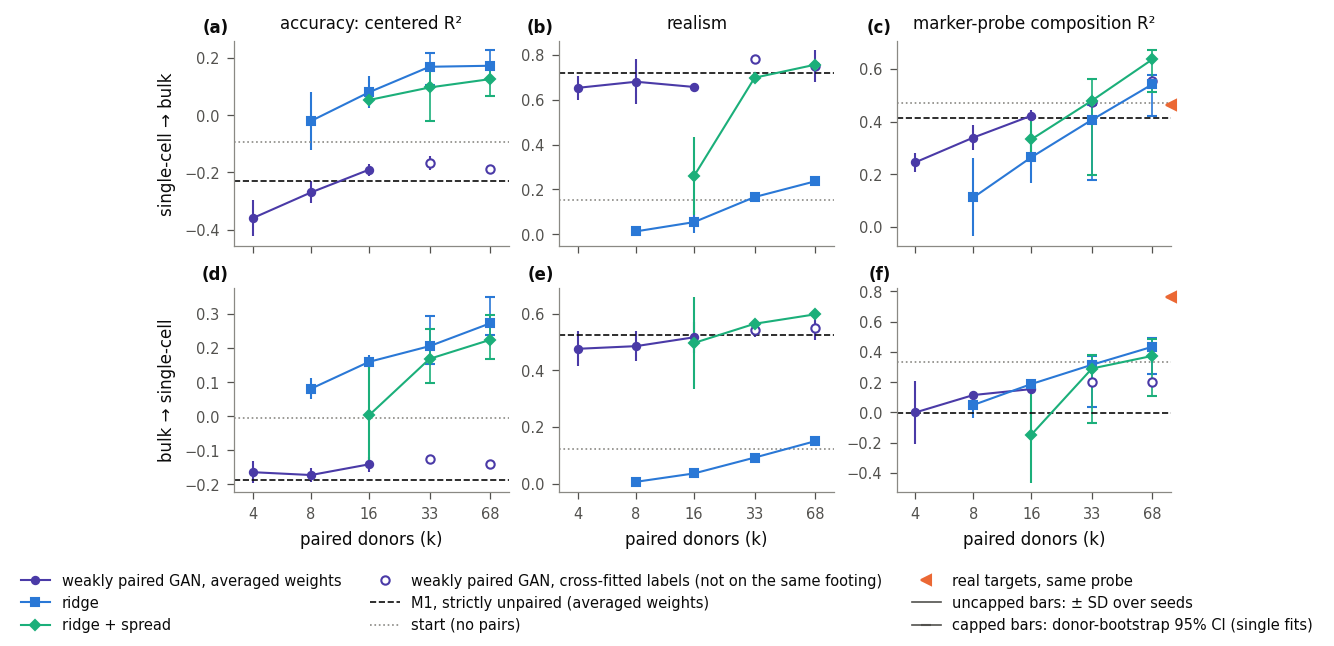

**Pairs buy far more accuracy as regression targets than as composition labels; in composition, labels lead only in single-cell → bulk with few paired donors.** Each panel plots one readout on the 135 validation pairs (14 donors) against the number of paired donors k (log scale): (a, d) accuracy, the centered R² (median over pairs of the R² against the real partner after removing each gene's training mean); (b, e) realism, 1 − 2|AUROC − 0.5| of a classifier two-sample test on the top 10 target principal components (1 = indistinguishable from real); (c, f) marker-probe composition R², the mean over six cell-type classes of the per-class R² of a ridge readout of composition from 28 lineage marker genes. Rows: (a–c) single-cell → bulk, (d–f) bulk → single-cell. Higher is better on every axis. Purple circles: the weakly paired CycleGAN, whose composition labels come from a bulk composition network trained on k donors' pairs (averaged weights; mean over seeds 6–8 of the mean over steps 15,000, 17,500 and 20,000; bars ± SD over seeds). At k = 4, 8 and 16 (filled) the donors are nested within one 16-donor pool per seed, so the SD includes the draw of donors, and the single-cell → bulk task term uses only the other 17 half-A donors; at k = 33 and 68 (open) the labels are cross-fitted over half A or all training donors and the points are not on the same footing. The GAN also trains on both full unpaired halves, while ridge sees only its k donors' pairs. Blue squares and green diamonds: paired ridge and ridge + spread (ridge with its output spread rescaled toward the real spread) trained on the k donors' pairs; at k = 8 and 16 means ± SD over the seeds' donor draws, at k = 33 and 68 single fits with donor-bootstrap 95% CIs (capped bars; 1,000 resamples of the 14 donors). Ridge + spread needs at least 16 donors. Horizontal lines: the strictly unpaired CycleGAN M1 (dashed; averaged weights) and the start the generators begin at (dotted; mean shift in single-cell → bulk, ComBat in bulk → single-cell; no pairs). In composition, the orange triangle on the right edge marks real targets read by the same probe (in single-cell → bulk a reference, not a ceiling, and nearly level with the start: 0.463 against 0.469). Ridge on 8 donors is already more accurate than the GAN with labels from all 68, and the GAN is more realistic than plain ridge at every k; its composition leads only in single-cell → bulk at k ≤ 16, and in bulk → single-cell it stays below the start at every k.

In [16]:
# Figure 6.1: what pairs buy, in absolute units: the three readouts against the number of paired donors.
from matplotlib.lines import Line2D
KS = [4, 8, 16, 33, 68]
STYLE = {"weakly paired GAN (EMA)": dict(color=SERIES[6], marker="o"), "ridge": dict(color=SERIES[0], marker="s"), "ridge + spread": dict(color=SERIES[2], marker="D")}
REF_STYLE = {"M1 (EMA)": dict(color=INK, ls="--"), "start": dict(color=MUTED, ls=":")}
REAL = dict(color=SERIES[1], marker="<", ms=5, ls="")              # real targets: a marker on the right edge (the line would overlay the start's)
TITLE = {"centered R²": "accuracy: centered R²", "realism": "realism", "marker composition R²": "marker-probe composition R²"}
fig, ax = figure("double", 4.2, 2, 3, sharex=True)
for i, d in enumerate(DIRS):
    for j, mname in enumerate(METRICS):
        a = ax[i, j]
        for meth, sty in STYLE.items():
            t = pb_tab[(pb_tab.direction == label(d)) & (pb_tab.method == meth) & (pb_tab.metric == mname)].sort_values("k")
            if not len(t):
                continue
            nested = t[t.footing == "nested"] if meth.startswith("weakly") else t
            a.errorbar(nested.k, nested.value, yerr=np.nan_to_num(nested["seed SD"].to_numpy(float)), lw=1, ms=3.5, capsize=0, **sty, label=meth)
            det = t[t["CI low"].notna()]                               # deterministic fits: donor-bootstrap 95% CI, capped
            if len(det):
                a.errorbar(det.k, det.value, yerr=[det.value - det["CI low"], det["CI high"] - det.value], ls="", marker=None, capsize=2.5, lw=0.8, color=sty["color"])
            if meth.startswith("weakly"):
                far = t[t.footing != "nested"]
                a.errorbar(far.k, far.value, yerr=far["seed SD"].astype(float), ls="", ms=4, mfc="white", capsize=0, lw=1, **sty)
        for rname, sty in REF_STYLE.items():
            v = ref_tab[(ref_tab.direction == label(d)) & (ref_tab.reference == rname)][mname].iloc[0]
            if np.isfinite(v):
                a.axhline(v, lw=0.8, **sty)
        v = ref_tab[(ref_tab.direction == label(d)) & (ref_tab.reference == "real targets")][mname].iloc[0]
        if np.isfinite(v):
            a.plot(1.0, v, transform=a.get_yaxis_transform(), clip_on=False, zorder=6, **REAL)
        a.set_xscale("log"); a.set_xticks(KS); a.set_xticklabels([str(k) for k in KS]); a.minorticks_off(); a.set_xlim(3.2, 85)
        a.set(xlabel="paired donors (k)" if i == 1 else "", ylabel=label(d) if j == 0 else "")
        if i == 0:
            a.set_title(TITLE[mname])
handles = [Line2D([], [], lw=1, ms=3.5, **STYLE[m], label=m.replace(" (EMA)", ", averaged weights")) for m in STYLE] + \
          [Line2D([], [], ls="", marker="o", mfc="white", color=SERIES[6], label="weakly paired GAN, cross-fitted labels (not on the same footing)")] + \
          [Line2D([], [], lw=0.8, **REF_STYLE[r], label={"M1 (EMA)": "M1, strictly unpaired (averaged weights)", "start": "start (no pairs)"}[r]) for r in REF_STYLE] + \
          [Line2D([], [], **REAL, label="real targets, same probe")] + \
          [Line2D([], [], color=INK_2, lw=0.8, marker="|", ms=0, label="uncapped bars: ± SD over seeds"),
           Line2D([], [], color=INK_2, lw=0.8, marker="_", ms=5, label="capped bars: donor-bootstrap 95% CI (single fits)")]
fig.legend(handles=handles, loc="outside lower center", ncol=3)
panel_labels(ax.ravel())
save_show(fig, FIG, "6.1_what_pairs_buy")
show_caption("6.1_what_pairs_buy")

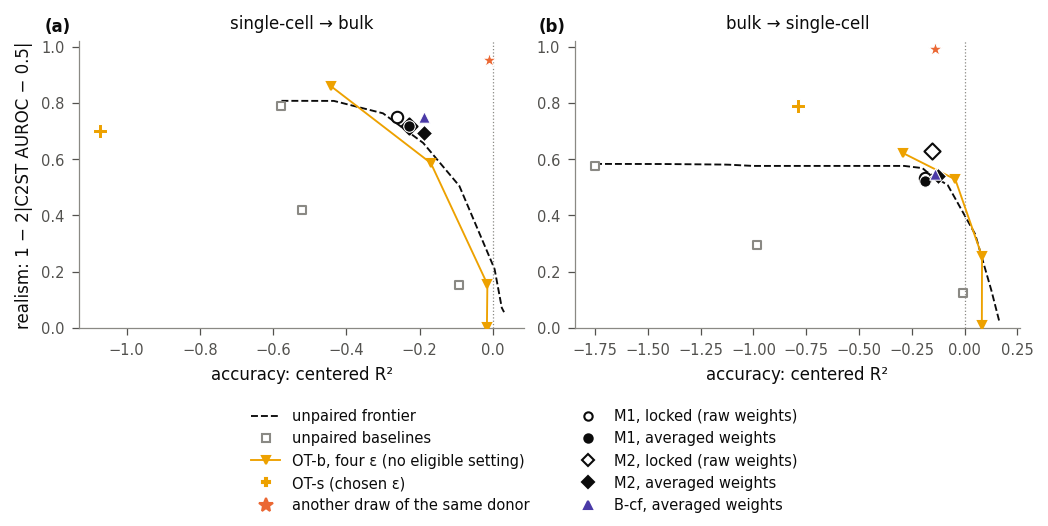

direction,model,margin,SD over seeds
single-cell → bulk,"M1, locked (raw weights, chosen checkpoints)",0.023,—
single-cell → bulk,"M2, locked (raw weights, chosen checkpoints)",0.022,—
single-cell → bulk,"M1, averaged weights (kept steps)",0.024,0.037
single-cell → bulk,"M2, averaged weights (kept steps)",0.047,0.012
single-cell → bulk,"B-cf, averaged weights (kept steps)",0.098,0.071
single-cell → bulk,another draw of the same donor,0.696,—
bulk → single-cell,"M1, locked (raw weights, chosen checkpoints)",-0.026,—
bulk → single-cell,"M2, locked (raw weights, chosen checkpoints)",0.086,—
bulk → single-cell,"M1, averaged weights (kept steps)",-0.036,0.033
bulk → single-cell,"M2, averaged weights (kept steps)",0.012,0.031


**The strictly unpaired M1 sits on the unpaired frontier; the weakly paired models can pass it, and every unpaired map that passes it copies or retrieves training profiles.** Each panel places translations of the 135 validation sources (14 donors) by accuracy (centered R², x-axis) and realism (1 − 2|C2ST AUROC − 0.5|, y-axis; both higher is better): (a) single-cell → bulk, (b) bulk → single-cell. The dashed curve is the unpaired frontier, the best realism reached at each accuracy by blending two of mean shift, ComBat, CORAL and the training-target mean (gray squares: the three baselines), all fit on the training halves. Black: the strictly unpaired CycleGAN M1 (circles) and the weakly paired M2 (diamonds), open for the locked models at their chosen checkpoints (raw weights, mean of seeds 0–2) and filled for averaged weights (mean over seeds 6–8 and steps 15,000, 17,500 and 20,000); purple triangle: B-cf, the weakly paired model with cross-fitted composition labels (averaged weights). Their margins are in Table 6.21: the weakly paired models are beyond the frontier in places (B-cf +0.098 in single-cell → bulk, locked M2 +0.086 in bulk → single-cell), using pair information the frontier's maps do not have. Yellow: entropic optimal transport fit on the same training halves; the line joins the barycentric map (OT-b) at regularization 0.01, 0.03, 0.1 and 0.3 × the median cost, from upper left (near-copies of single training profiles) to lower right (collapse toward the training mean); no setting met the memorization rule, so none is marked as chosen. The plus is OT-s, one training profile drawn per source at the chosen regularization (mean of 3 draws). The orange star is a real profile from another draw of the same donor, scored as a translation. The dotted vertical line marks centered R² = 0. The unpaired points beyond the frontier are real or retrieved profiles (the star; OT-s in bulk → single-cell) or OT-b with outputs close to training profiles (smallest regularization in both directions; also ε = 0.03 and 0.1 in bulk → single-cell, memorization ratios 0.55–0.67), so passing the frontier on this realism measure does not by itself mean a translation carries information about its source.

In [17]:
# Figure 6.2: the accuracy-realism plane with the averaged-weight models, OT and the same-donor reference.
halves = pd.read_csv(paths.results_dir(1) / "baselines_val_halves.csv")
p3 = pd.read_csv(paths.results_dir(3) / "models_vs_baselines_val.csv")
fig, ax = figure("double", 3.4, 1, 2)
for a, d in zip(ax, DIRS):
    env = envelope(ctx0.frontier[d])
    a.plot(env["r2_centered"], env["realism"], color=INK, lw=0.9, ls="--", zorder=1)
    for k, name in enumerate(("mean shift", "ComBat", "CORAL")):
        r = halves[(halves.halving == 0) & (halves.direction == d) & (halves.baseline == name)].iloc[0]
        a.scatter(r["r2_centered"], 1 - 2 * abs(r["c2st_auroc"] - 0.5), s=18, marker="s", facecolor="white", edgecolor=MUTED, lw=1, zorder=2)
    for m, mk in (("M1", "o"), ("M2", "D")):
        r = p3[(p3.direction == label(d)) & (p3.method == f"{m} (mean of 3 seeds)")].iloc[0]
        a.scatter(r["r2_centered"], r["realism"], s=30, marker=mk, facecolor="white", edgecolor=INK, lw=1, zorder=4)
    for runs, mk, col in ((ema_m1, "o", INK), (ema_m2, "D", INK), (ema_bcf, "^", SERIES[6])):
        a.scatter(kept_ema(runs, d, "r2_centered")[0], kept_ema(runs, d, "realism")[0], s=30, marker=mk, color=col, edgecolor="white", lw=0.5, zorder=5)
    t = ot_tab[(ot_tab.variant == "OT-b") & (ot_tab.direction == label(d))].sort_values("eps")
    a.plot(t["centered R²"], t["realism"], color=SERIES[3], lw=0.9, marker="v", ms=3.5, zorder=3)
    if EPS_B is not None:
        c = t[t.eps == EPS_B].iloc[0]
        a.scatter(c["centered R²"], c["realism"], s=40, marker="v", color=SERIES[3], edgecolor=INK, lw=0.6, zorder=6)
    c = ot_tab[(ot_tab.variant == "OT-s") & (ot_tab.direction == label(d)) & (ot_tab.eps == EPS_S)].iloc[0]
    a.scatter(c["centered R²"], c["realism"], s=40, marker="P", color=SERIES[3], edgecolor="white", lw=0.5, zorder=6)
    s_ = same_donor[d]
    a.scatter(s_["centered R²"], s_["realism"], s=50, marker="*", color=SERIES[1], edgecolor="white", lw=0.5, zorder=6)
    a.axvline(0, color=MUTED, lw=0.6, ls=":")
    a.set(xlabel="accuracy: centered R²", ylabel="realism: 1 − 2|C2ST AUROC − 0.5|" if d == "S->B" else "", title=label(d), ylim=(0, 1.02))
handles = [Line2D([], [], color=INK, lw=0.9, ls="--", label="unpaired frontier"),          # left column: unpaired maps and the reference
           Line2D([], [], ls="", marker="s", mfc="white", mec=MUTED, label="unpaired baselines"),
           Line2D([], [], color=SERIES[3], marker="v", ms=3.5, lw=0.9, label="OT-b, four ε (outlined: chosen)" if EPS_B is not None else "OT-b, four ε (no eligible setting)"),
           Line2D([], [], ls="", marker="P", color=SERIES[3], label="OT-s (chosen ε)"),
           Line2D([], [], ls="", marker="*", ms=7, color=SERIES[1], label="another draw of the same donor"),
           Line2D([], [], ls="", marker="o", mfc="white", mec=INK, label="M1, locked (raw weights)"),  # right column: the GANs
           Line2D([], [], ls="", marker="o", color=INK, label="M1, averaged weights"),
           Line2D([], [], ls="", marker="D", mfc="white", mec=INK, label="M2, locked (raw weights)"),
           Line2D([], [], ls="", marker="D", color=INK, label="M2, averaged weights"),
           Line2D([], [], ls="", marker="^", color=SERIES[6], label="B-cf, averaged weights")]
fig.legend(handles=handles, loc="outside lower center", ncol=2, columnspacing=3.0)
panel_labels(ax)
save_show(fig, FIG, "6.2_plane")
pm_rows = []
for d in DIRS:
    for m in ("M1", "M2"):
        r = p3[(p3.direction == label(d)) & (p3.method == f"{m} (mean of 3 seeds)")].iloc[0]
        pm_rows.append({"direction": label(d), "model": f"{m}, locked (raw weights, chosen checkpoints)", "margin": r["margin at the chosen checkpoint"]})
    for nm, runs in (("M1", ema_m1), ("M2", ema_m2), ("B-cf", ema_bcf)):
        v, sd = kept_ema(runs, d, "margin")
        pm_rows.append({"direction": label(d), "model": f"{nm}, averaged weights (kept steps)", "margin": v, "SD over seeds": sd})
    pm_rows.append({"direction": label(d), "model": "another draw of the same donor", "margin": same_donor[d]["margin"]})
pm_tab = pd.DataFrame(pm_rows)
pm_tab.to_csv(RESULTS / "plane_margins_val.csv", index=False)
display(tidy(pm_tab.style.format("{:.3f}", na_rep="—", subset=["margin", "SD over seeds"]).hide(axis="index")
        .set_caption("Table 6.21. Margin beyond the unpaired frontier of the models drawn in Figure 6.2, validation")))
show_caption("6.2_plane")

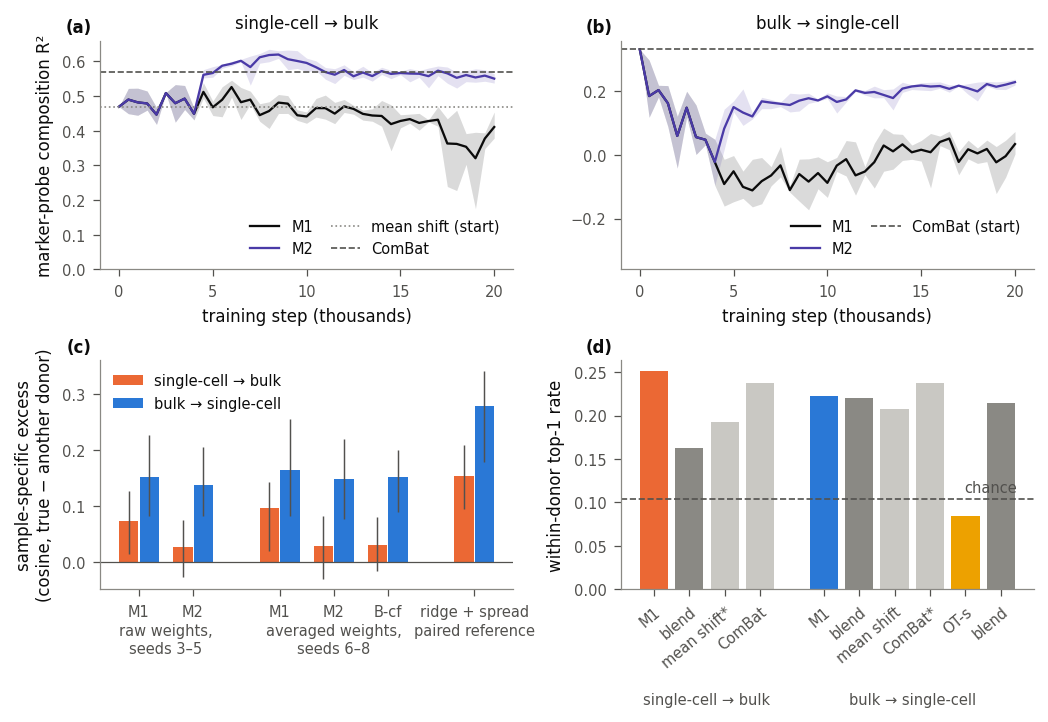

**Adversarial training lowers composition and labels partly restore it; what M1 gets right about each sample is close to what ComBat gets right.** (a, b) Marker-probe composition R² of the validation translations (135 pairs, 14 donors) over training, for M1 (black) and M2 (purple), fresh seeds 3–5 with raw weights (line: mean; band: range over seeds), with the composition of unpaired baseline maps as horizontal lines: (a) single-cell → bulk, with the mean-shift start (dotted) and ComBat (dashed); (b) bulk → single-cell, with the ComBat start (dashed). The task loss starts at step 4,000 and reaches full weight at step 8,000. (c) The sample-specific excess of the move from the start: the median cosine between the move δ = G(x) − s(x) and the needed correction y − s(x), minus the same median with another donor's real profile in place of y, with donor-bootstrap 95% CIs (1,000 resamples of the 14 donors); orange single-cell → bulk, blue bulk → single-cell; groups: raw weights (seeds 3–5, steps 15,000, 17,500, 20,000), averaged weights (seeds 6–8, same steps), and paired ridge + spread fit on all training pairs. (d) Within-donor top-1 rate (the share of samples, among donors with several draws, whose translation is closest to its own partner among that donor's draws) of M1 (fresh seeds, raw weights), its matched blend (dark gray; the most realistic blend of two unpaired baselines with M1's centered R²) and the unpaired maps on their own (light gray; the asterisk marks each direction's start; CORAL is not drawn, since in single-cell → bulk it equals the matched blend), and in bulk → single-cell of OT-s next to its matched blend; OT-s has no matched blend in single-cell → bulk, where it is less accurate than every blend. The dashed line is chance (0.104). In single-cell → bulk M1 (0.251) is ahead of its matched blend (0.163), slightly ahead of its start (0.193; difference +0.058, 95% CI −0.001 to 0.113) and close to ComBat (0.237); in bulk → single-cell it is within 0.016 of every map.

In [18]:
# Figure 6.3: mechanism. (a, b) marker-probe composition over training (fresh seeds, raw weights) with the start lines;
# (c) the sample-specific excess of the move from the start; (d) within-donor top-1 of M1, its matched blend and OT.
fig, axs = figure("double", 4.7, 2, 2)
ax = list(axs.ravel())
for a, d in zip(ax[:2], DIRS):
    for runs, col, nm in ((fresh_m1, INK, "M1"), (fresh_m2, SERIES[6], "M2")):
        ev = np.array([[e[f"{d} marker comp_r2"] for e in r["evals"]] for r in runs])
        steps = [e["step"] for e in runs[0]["evals"]]
        a.plot(steps, ev.mean(0), color=col, lw=1.1, label=nm)
        a.fill_between(steps, ev.min(0), ev.max(0), color=col, alpha=0.15, lw=0)
    lines = (("mean shift", "mean shift (start)", dict(color=MUTED, ls=":")), ("ComBat", "ComBat", dict(color=INK_2, ls="--"))) if d == "S->B" \
        else (("ComBat", "ComBat (start)", dict(color=INK_2, ls="--")),)    # bulk -> single-cell: mean shift reads -1.45, off the scale
    for nm, lab_, sty in lines:
        a.axhline(comp.comp_r2(marker(members[d][nm], d), Cv), lw=0.8, **sty, label=lab_)
    a.set(xlabel="training step (thousands)", ylabel="marker-probe composition R²" if d == "S->B" else "", title=label(d))
    a.xaxis.set_major_locator(plt.MultipleLocator(5000)); a.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:g}"))
    a.set_ylim((0.0, 0.66) if d == "S->B" else (-0.36, 0.36))     # room below the curves for the legend
    a.legend(loc="lower right", ncol=2, columnspacing=1.2)
names = ["M1, fresh seeds (raw)", "M2, fresh seeds (raw)", "M1 (EMA)", "M2 (EMA)", "B-cf (EMA)", "ridge + spread (all training pairs)"]
show_n = {"M1, fresh seeds (raw)": "M1", "M2, fresh seeds (raw)": "M2", "M1 (EMA)": "M1", "M2 (EMA)": "M2", "B-cf (EMA)": "B-cf",
          "ridge + spread (all training pairs)": "ridge + spread"}
xx = np.array([0, 1, 2.6, 3.6, 4.6, 6.2])                              # gaps between the raw, averaged and paired groups
for k, d in enumerate(DIRS):
    t = mv_tab[mv_tab.direction == label(d)].set_index("translations").loc[names]
    lo = np.array([float(s.split(" to ")[0]) for s in t["sample-specific excess CI"]]); hi = np.array([float(s.split(" to ")[1]) for s in t["sample-specific excess CI"]])
    ax[2].bar(xx + (k - 0.5) * 0.38, t["sample-specific excess"], width=0.36, color=DOMAIN["bulk" if d == "S->B" else "single-cell"], label=label(d),
              yerr=[t["sample-specific excess"] - lo, hi - t["sample-specific excess"]], error_kw=dict(lw=0.7, ecolor=INK_2))
ax[2].axhline(0, color=INK_2, lw=0.6)
for x0, txt in ((0.5, "raw weights,\nseeds 3–5"), (3.6, "averaged weights,\nseeds 6–8"), (6.2, "paired reference")):
    ax[2].text(x0, -0.15, txt, transform=ax[2].get_xaxis_transform(), ha="center", va="top", fontsize=7, color=INK_2)
ax[2].set_xticks(xx, [show_n[n] for n in names])
ax[2].set(ylabel="sample-specific excess\n(cosine, true − another donor)")
ax[2].legend(loc="upper left")
bt = blend_tab.set_index(["direction", "translations"])
pdt = pd_tab[pd_tab.translations == "M1, fresh seeds (raw)"].set_index(["direction", "unpaired map"])
xs, vals, cols, ticks, groups = [], [], [], [], []
x = 0.0
for d in DIRS:
    start_x = x
    r = bt.loc[(label(d), "M1, fresh seeds (raw)")]
    bars = [("M1", r["within-donor top-1, model"], DOMAIN["bulk" if d == "S->B" else "single-cell"]), ("blend", r["within-donor top-1, blend"], MUTED)]
    bars += [({"mean shift": "mean shift", "mean shift (start)": "mean shift*", "ComBat": "ComBat", "ComBat (start)": "ComBat*"}[nm],
              pdt.loc[(label(d), nm), "within-donor top-1, map"], "#c9c8c3")
             for nm in pdt.loc[label(d)].index if not nm.startswith("CORAL")]   # CORAL equals the blend here
    if (label(d), "OT-s (chosen ε)") in bt.index and np.isfinite(bt.loc[(label(d), "OT-s (chosen ε)"), "within-donor top-1, model"]):
        o = bt.loc[(label(d), "OT-s (chosen ε)")]
        bars += [("OT-s", o["within-donor top-1, model"], SERIES[3]), ("blend", o["within-donor top-1, blend"], MUTED)]
    for who, v, c in bars:
        xs.append(x); vals.append(v); cols.append(c); ticks.append(who); x += 1
    groups.append(((start_x + x - 1) / 2, label(d)))
    x += 0.8
ax[3].bar(xs, vals, color=cols, width=0.8)
chance = float(np.mean(1 / pd.Series(donors_va).map(pd.Series(donors_va).value_counts()).to_numpy()))
ax[3].axhline(chance, **THRESHOLD)
ax[3].text(xs[-1] + 0.45, chance + 0.004, "chance", ha="right", va="bottom", fontsize=7, color=INK_2)
ax[3].set_xticks(xs, ticks, fontsize=7, rotation=40, ha="right", rotation_mode="anchor")
for x0, txt in groups:
    ax[3].text(x0, -0.45, txt, transform=ax[3].get_xaxis_transform(), ha="center", va="top", fontsize=7, color=INK_2)
ax[3].set(ylabel="within-donor top-1 rate")
panel_labels(ax)
save_show(fig, FIG, "6.3_mechanism")
show_caption("6.3_mechanism")

## 5. Conclusions

- **Without pairs, adversarial training buys realism but little information.** At its own accuracy M1 is about as realistic as a blend of unpaired baselines. Its sample-level signal is small: in single-cell → bulk it identifies its sample within the donor better than its matched blend, which has CORAL's discrimination (+0.088, 95% CI 0.040–0.138, fresh seeds), and slightly better than its start (+0.058, 95% CI −0.001 to 0.113; averaged weights +0.062, 95% CI 0.013–0.106), but about as well as ComBat (+0.014, 95% CI −0.034 to 0.066); in bulk → single-cell it does no better than any baseline.
- **Adversarial training costs composition** (averaged weights): M1 is below ComBat in single-cell → bulk (−0.157, 95% CI −0.278 to −0.078) and below its ComBat start in bulk → single-cell (−0.335, 95% CI −0.570 to −0.244), mostly in T, NK and dendritic cells.
- **Pairs pay off far more as regression targets than as composition labels in accuracy**, at every number of paired donors. In composition, labels lead only in single-cell → bulk with few donors, and paired regression passes them with all 68; in bulk → single-cell, ridge leads from 16 donors and the labels leave the GAN below the no-pairs ComBat start (B-cf −0.134, 95% CI −0.286 to −0.067).
- **Part of the weakly paired models' composition gain reflects their training readout**: in single-cell → bulk the marker probe sees less than half of the gain under the trained-against network (transfer ratio 0.42–0.47 in all three comparisons, point estimates; only the fresh-seed CI lies wholly below 0.5), and so does B-cf in bulk → single-cell (0.487, 95% CI 0.389–0.582, at the threshold). A retrained copy of the network sees almost all of it and the translations are about as easy to attack as real inputs, so this is disagreement between readouts, not exploitation of one network's weights.
- **The checks find no hidden channel and no copying by the GANs, and the one non-adversarial unpaired map we tried does no better.** The cycle shows no sign of a low-amplitude hidden channel under this test, and no GAN copies its training targets. Entropic optimal transport passes the frontier only where it copies training profiles, and returning real training profiles passes it on realism alone in bulk → single-cell. A positive frontier margin needs a partner-discrimination check before it can be read as information.

All estimates are on the validation donors that chose the models, so they are optimistic for the models.

**Implications for the test evaluation.** The test evaluation scores the locked models, the baselines and the exploratory models below once, on 119 pairs from 14 donors.
- **Hypothesis H1 (M1 beyond the unpaired frontier), per direction.** The pre-specified reading is set by the confidence interval of the margin:
  - *above 0*: "supported on halving 0", with the qualifier "not robust to the training split" if the halving-1 test margin is at or below 0. The halving-1 validation margin in bulk → single-cell (−0.332, Table 6.3) makes the qualifier likely in that direction;
  - *including 0*: "not distinguishable from the unpaired frontier", the likely reading with 14 donors, consistent with M1 sitting on the frontier on validation;
  - *below 0*: "inside the unpaired frontier", plausible in bulk → single-cell, where M1's validation margin with averaged weights is −0.036 ± 0.033 (Table 6.21).

  Each reading comes with the share of bootstrap resamples whose margin is of the realism kind and of the accuracy kind, the realism-margin CI over the realism-kind resamples only, and, in one line, the superseded per-metric form of H1 that the frontier criterion replaced (beat the best unpaired baseline on centered R² and on realism separately; Phase 3, §3.4). Because profiles that carry no information pass the frontier (§4.1, §4.6), the H1 result is reported next to M1's within-donor top-1 against the start and ComBat.
- **Hypothesis H2 (M2 beats M1 on marker-probe composition), per direction.** Two readings: "supported" (CI above 0) or "not supported". In single-cell → bulk either reading carries the label "the generator partly fits its training readout" (§4.2; the label rests on the point estimate, and the locked comparison's ratio CI, 0.288–0.671, includes the threshold), and in both directions the statement that M2's composition networks were trained on pairs that include the training donors' own.
- **Multiplicity.** Four primary intervals (H1 and H2 in each direction), per direction and uncorrected, as fixed before Phase 3; H3 (ridge + spread against the unpaired models) is reported with intervals and no claim.
- **B-cf on test (exploratory, weakly paired).** Seeds 6–8, averaged weights at steps 15,000, 17,500 and 20,000, no checkpoint selection. Primary per direction: paired donor-bootstrap CIs of the difference in marker-probe composition R² and in centered R² from M1 with averaged weights. Secondary: the same against M2 with averaged weights, realism, within-donor top-1, its frontier margin (descriptive), and the differences from the locked models, labeled as mixing raw and averaged weights. No multiplicity correction, and no comparison with H1. It carries the §4.2 label in both directions, the count of 56 settings and 160 runs compared on these validation donors, and the statement that its design used validation results; it has no halving-1 check.
- **Optimal transport on test.** OT-b had no eligible setting and does not go to test; OT-s at ε = 0.3 is reported on test descriptively, as retrieval.
- **Compute.** The H1 frontier bootstrap takes about 5 hours for M1; everything else takes minutes, so the test evaluation fits in one overnight run on a laptop.

## 6. Limitations

- **Validation only, on the donors that chose the models.** Every estimate is optimistic for the models, and 14 donors give wide intervals. The donor-bootstrap CIs cover donor sampling, not training noise, and realism and margins have no validation CI.
- **Three seeds per readout,** so the seed SDs are themselves noisy. The transfer-ratio rule acts on point estimates: in single-cell → bulk only the fresh-seed CI lies wholly below 0.5, and B-cf's bulk → single-cell ratio sits at the threshold.
- **The retrained composition network rules out only seed-specific exploitation.** It shares the configuration, epochs and training rows of the original and differs mainly in training order, so it cannot show whether the generators exploit the network family.
- **The independent readout is a 28-marker linear probe** that recovers composition from real bulk only moderately in single-cell → bulk, so part of the gap between the readers may reflect the probe rather than the generator.
- **The realism measure sees only the top 10 principal components,** and every statement relative to the frontier inherits that.
- **One non-adversarial comparator:** entropic optimal transport with one cost (squared distance in the targets' top 50 principal components) and four regularization settings. It does not show that no unpaired method could pass the frontier with information about the source.
- **The steganography check tests one kind of hidden signal:** Gaussian noise at three amplitudes, in the top 50 components, outside them and per gene. Other encodings are not ruled out.
- **The memorization ratio does not separate copying from shrinkage toward the training mean;** both lower it.
- **Training-split sensitivity** (halving 1) exists for the locked M1 and M2 (Phase 3) and for optimal transport (Table 6.3), but not for B-cf.
- **Single cohort,** with PBMC-derived single-cell profiles against whole-blood bulk, as in every phase.

## 7. Reproducibility

- **Runtime and hardware:** with the caches below the notebook runs in about 6 minutes on a 24-thread Intel Core Ultra 9 275HX; without them, the ε₅₀ attack adds about 7 minutes on 4 CPU threads. No translation model is trained here.
- **Determinism:** CPU only, with torch and the BLAS/OpenMP pools pinned to 4 threads and deterministic algorithms (`dgm.composition.deterministic`); fixed seeds for the donor bootstrap, the optimal-transport draws, the noise draws and the other-donor pairing. A re-run reproduces every CSV byte for byte.
- **Code:** `dgm/analysis.py` (matched blend, alignment, information-free map, gap closure and transfer, noise and sensitivity, same-donor reference, similarity, donor bootstrap), `dgm/ot.py` (Sinkhorn and the two maps), and the shared modules of Phases 1–5. Known-answer tests: `python -m tests.test_phase6`.
- **Inputs:** the saved generators of Phases 3–5, reloaded from their run caches (`data/processed/phase4`, `data/processed/phase5`) and the Phase 3 model files, each checked against its phase's registry hash or per-run table before use; the Phase 1–5 result tables; the frozen composition networks and marker probes of Phases 2, 4 and 5.
- **Caches:** the attack (`eps50.pkl`) and the matched blends (`matched_blends.pkl`) in `data/processed/phase6`, each keyed on its inputs; delete a file to recompute it. The retrained composition networks are in `data/models/phase6`, with hashes in `results/phase6/models.json`; they are retrained when the registry entry is missing or its configuration, epochs or member seeds differ. Setting `PHASE6_SMOKE=1` runs the attack on 6 samples, to test the code only.

**Outputs in `results/phase6/`:**
- `ot_sweep_val.csv` (Tables 6.1–6.2), `ot_sweep_ci_val.csv` (Table 6.2, continued), `ot_halving1_val.csv` (Table 6.3);
- `exploitation_closure_val.csv` (Tables 6.4 and 6.6), `exploitation_transfer_val.csv` (Table 6.5), `exploitation_eps50_val.csv` (Table 6.7);
- `matched_blend_val.csv` (Tables 6.8–6.9), `partner_vs_baselines_val.csv` (Table 6.9, continued), `info_free_map_val.csv` (Table 6.10), `move_decomposition_ci_val.csv` (Table 6.11);
- `lineage_composition_val.csv` (Table 6.12), `lineage_composition_raw_val.csv` (Table 6.13), `composition_vs_start_val.csv` (Table 6.13, continued);
- `pairs_buy_val.csv` (Table 6.14), `pairs_buy_references_val.csv` (Table 6.15);
- `same_donor_reference_val.csv` (Table 6.16), `donor_recovery_val.csv` (Table 6.17);
- `steganography_runs_val.csv` (per run) and `steganography_val.csv` (Table 6.18), `memorization_val.csv` (Table 6.19), `configuration_count.csv` (Table 6.20), `plane_margins_val.csv` (Table 6.21);
- `figures/`: Figures 6.1–6.3 as PNG and PDF, with their captions in `captions.md`.

## References

- Chu, C., Zhmoginov, A. & Sandler, M. CycleGAN, a master of steganography. *NIPS Workshop on Machine Deception* (2017). arXiv:1712.02950.
- Cuturi, M. Sinkhorn distances: lightspeed computation of optimal transport. *NeurIPS* (2013).
- Hoffman, J., Tzeng, E., Park, T., Zhu, J.-Y., Isola, P., Saenko, K., Efros, A. A. & Darrell, T. CyCADA: cycle-consistent adversarial domain adaptation. *ICML* (2018).
- Johnson, W. E., Li, C. & Rabinovic, A. Adjusting batch effects in microarray expression data using empirical Bayes methods. *Biostatistics* 8, 118–127 (2007).
- Lopez-Paz, D. & Oquab, M. Revisiting classifier two-sample tests. *ICLR* (2017).
- Madry, A., Makelov, A., Schmidt, L., Tsipras, D. & Vladu, A. Towards deep learning models resistant to adversarial attacks. *ICLR* (2018).
- Mao, X., Li, Q., Xie, H., Lau, R. Y. K., Wang, Z. & Smolley, S. P. Least squares generative adversarial networks. *ICCV*, 2813–2821 (2017).
- Pooladian, A.-A. & Niles-Weed, J. Entropic estimation of optimal transport maps. arXiv:2109.12004 (2021).
- Sun, B., Feng, J. & Saenko, K. Return of frustratingly easy domain adaptation. *AAAI* (2016).
- Zhu, J.-Y., Park, T., Isola, P. & Efros, A. A. Unpaired image-to-image translation using cycle-consistent adversarial networks. *ICCV* (2017).